# VANET Updated Notebook: 80% Baseline Reproduction + Leakage Audit

This notebook keeps the leakage/shortcut audit and adds the **80%+ baseline reproduction mode**.

Important experimental setting:
- `NORMAL_DATASET_MODE = 'highway_2'` reproduces the earlier high-accuracy setting where normal data comes from `InTAS_highway_2` and DoS attack data comes from `InTAS_urban_2_dosAttack`.
- This setting usually gives an attack-dominant test sample close to `normal ≈ 6,569` and `dosAttack ≈ 43,431` when 50,000 test samples are drawn.
- `NORMAL_DATASET_MODE = 'urban_2'` is the stricter same-scenario setting, but it may produce much lower mobility-only performance.

The notebook therefore reports accuracy, attack F1, Macro-F1, Balanced Accuracy, and ROC-AUC so that accuracy is not interpreted alone.


In [60]:
# ============================================================
# 1. IMPORTS
# ============================================================

!pip install -q tqdm

import os, json, zipfile, warnings
import numpy as np
import pandas as pd
from tqdm import tqdm
from io import StringIO

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
np.random.seed(42)
print("Ready.")

Ready.


In [61]:
# ============================================================
# 2. MOUNT DRIVE AND SET DATASET PATH
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/Vanet Dataset"

print("Dataset folder exists:", os.path.exists(DATA_DIR))
print(os.listdir(DATA_DIR) if os.path.exists(DATA_DIR) else "Folder not found")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset folder exists: True
['InTAS_urban_7', 'InTAS_highway_2', 'InTAS_urban_2', 'InTAS_urban_2_dosAttack']


In [62]:
# ============================================================
# 3. SELECT SCENARIOS
# ============================================================
# To reproduce the earlier 80%+ result, keep NORMAL_DATASET_MODE = "highway_2".
# Earlier high result came from an attack-dominant test composition where normal
# samples were from InTAS_highway_2 and DoS samples were from InTAS_urban_2_dosAttack.
#
# For stricter same-scenario evaluation, change NORMAL_DATASET_MODE to "urban_2".
# That stricter setting is more conservative but may reduce performance substantially.
# ============================================================

NORMAL_DATASET_MODE = "highway_2"   # options: "highway_2" or "urban_2"
DOS_DATASET_MODE = "urban_2_dosAttack"

if NORMAL_DATASET_MODE == "highway_2":
    normal_folder = "InTAS_highway_2"
    normal_zip = "InTAS_highway_2.zip"
elif NORMAL_DATASET_MODE == "urban_2":
    normal_folder = "InTAS_urban_2"
    normal_zip = "InTAS_urban_2.zip"
else:
    raise ValueError("NORMAL_DATASET_MODE must be 'highway_2' or 'urban_2'")

selected_scenarios = {
    "normal": {
        "Train": os.path.join(DATA_DIR, normal_folder, normal_folder, "Train", normal_zip),
        "Validation": os.path.join(DATA_DIR, normal_folder, normal_folder, "Validation", normal_zip),
        "Test": os.path.join(DATA_DIR, normal_folder, normal_folder, "Test", normal_zip),
    },
    "dosAttack": {
        "Train": os.path.join(DATA_DIR, "InTAS_urban_2_dosAttack", "InTAS_urban_2_dosAttack", "Train", "InTAS_urban_2_dosAttack.zip"),
        "Validation": os.path.join(DATA_DIR, "InTAS_urban_2_dosAttack", "InTAS_urban_2_dosAttack", "Validation", "InTAS_urban_2_dosAttack.zip"),
        "Test": os.path.join(DATA_DIR, "InTAS_urban_2_dosAttack", "InTAS_urban_2_dosAttack", "Test", "InTAS_urban_2_dosAttack.zip"),
    }
}

print("NORMAL_DATASET_MODE:", NORMAL_DATASET_MODE)
print("DOS_DATASET_MODE:", DOS_DATASET_MODE)

for scenario, splits in selected_scenarios.items():
    print("\nScenario:", scenario)
    for split, path in splits.items():
        print(split, "->", os.path.exists(path), path)


NORMAL_DATASET_MODE: highway_2
DOS_DATASET_MODE: urban_2_dosAttack

Scenario: normal
Train -> True /content/drive/MyDrive/Vanet Dataset/InTAS_highway_2/InTAS_highway_2/Train/InTAS_highway_2.zip
Validation -> True /content/drive/MyDrive/Vanet Dataset/InTAS_highway_2/InTAS_highway_2/Validation/InTAS_highway_2.zip
Test -> True /content/drive/MyDrive/Vanet Dataset/InTAS_highway_2/InTAS_highway_2/Test/InTAS_highway_2.zip

Scenario: dosAttack
Train -> True /content/drive/MyDrive/Vanet Dataset/InTAS_urban_2_dosAttack/InTAS_urban_2_dosAttack/Train/InTAS_urban_2_dosAttack.zip
Validation -> True /content/drive/MyDrive/Vanet Dataset/InTAS_urban_2_dosAttack/InTAS_urban_2_dosAttack/Validation/InTAS_urban_2_dosAttack.zip
Test -> True /content/drive/MyDrive/Vanet Dataset/InTAS_urban_2_dosAttack/InTAS_urban_2_dosAttack/Test/InTAS_urban_2_dosAttack.zip


In [63]:
# ============================================================
# 4. ROBUST VeReMi / InTAS ZIP LOADER
# ============================================================

def flatten_json(obj, prefix=""):
    out = {}
    if isinstance(obj, dict):
        for k, v in obj.items():
            nk = f"{prefix}_{k}" if prefix else str(k)
            out.update(flatten_json(v, nk))
    elif isinstance(obj, list):
        for i, v in enumerate(obj[:10]):
            nk = f"{prefix}_{i}" if prefix else str(i)
            out.update(flatten_json(v, nk))
    else:
        out[prefix] = obj
    return out

def dict_or_list_to_rows(obj, max_records=None):
    rows = []
    if isinstance(obj, list):
        for item in obj:
            if isinstance(item, dict):
                rows.append(flatten_json(item))
            if max_records and len(rows) >= max_records:
                break
    elif isinstance(obj, dict):
        found = False
        for key, val in obj.items():
            if isinstance(val, list) and len(val) > 0 and isinstance(val[0], dict):
                found = True
                for item in val:
                    row = flatten_json(item)
                    row["_parent_key"] = key
                    rows.append(row)
                    if max_records and len(rows) >= max_records:
                        break
            if max_records and len(rows) >= max_records:
                break
        if not found:
            rows.append(flatten_json(obj))
    return rows

def parse_text_to_rows(text, max_records=None):
    text = text.strip()
    if not text:
        return []

    try:
        obj = json.loads(text)
        rows = dict_or_list_to_rows(obj, max_records=max_records)
        if rows:
            return rows
    except Exception:
        pass

    rows = []
    for line in text.splitlines():
        line = line.strip()
        if not line:
            continue
        try:
            obj = json.loads(line)
            rows.extend(dict_or_list_to_rows(obj))
        except Exception:
            continue
        if max_records and len(rows) >= max_records:
            return rows[:max_records]
    if rows:
        return rows[:max_records] if max_records else rows

    decoder = json.JSONDecoder()
    idx, n = 0, len(text)
    while idx < n:
        while idx < n and text[idx] not in "{[":
            idx += 1
        if idx >= n:
            break
        try:
            obj, end = decoder.raw_decode(text[idx:])
            rows.extend(dict_or_list_to_rows(obj))
            idx += end
        except Exception:
            idx += 1
        if max_records and len(rows) >= max_records:
            return rows[:max_records]
    return rows[:max_records] if max_records else rows

def read_zip_member_text(zip_obj, member_name):
    with zip_obj.open(member_name) as f:
        raw = f.read()
    try:
        return raw.decode("utf-8")
    except Exception:
        return raw.decode("latin-1", errors="ignore")

def load_one_zip(zip_path, scenario_label, split_label,
                 max_records_per_inner_file=12000,
                 max_inner_files=250,
                 debug_first_file=False):
    dfs = []
    with zipfile.ZipFile(zip_path, "r") as z:
        inner_files = z.namelist()
        candidates = []
        for f in inner_files:
            lower = f.lower()
            base = os.path.basename(lower)
            if lower.endswith("/"):
                continue
            if lower.endswith((".json", ".jsonl", ".ndjson", ".txt", ".log", ".csv")) or "." not in base:
                candidates.append(f)

        print(f"Reading {scenario_label}/{split_label}: inner files={len(inner_files)}, candidates={len(candidates)}")

        if debug_first_file and candidates:
            first = candidates[0]
            print("--- First candidate:", first, "---")
            print(read_zip_member_text(z, first)[:1000])
            print("--- End preview ---")

        for fname in tqdm(candidates[:max_inner_files]):
            try:
                lower = fname.lower()
                text = read_zip_member_text(z, fname)
                if lower.endswith(".csv"):
                    df_temp = pd.read_csv(StringIO(text), nrows=max_records_per_inner_file)
                else:
                    rows = parse_text_to_rows(text, max_records=max_records_per_inner_file)
                    if not rows:
                        continue
                    df_temp = pd.DataFrame(rows)
                if len(df_temp) == 0:
                    continue
                df_temp["source_file"] = fname
                df_temp["scenario_label"] = scenario_label
                df_temp["split"] = split_label
                dfs.append(df_temp)
            except Exception:
                continue

    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()

def load_selected_scenarios(selected_scenarios,
                            max_records_per_inner_file=12000,
                            max_inner_files=250,
                            debug_first_file=False):
    dfs = []
    for scenario_label, split_paths in selected_scenarios.items():
        for split_label, zip_path in split_paths.items():
            if not os.path.exists(zip_path):
                print("Missing:", zip_path)
                continue
            df_temp = load_one_zip(
                zip_path, scenario_label, split_label,
                max_records_per_inner_file=max_records_per_inner_file,
                max_inner_files=max_inner_files,
                debug_first_file=debug_first_file
            )
            print(" Loaded shape:", df_temp.shape)
            if len(df_temp) > 0:
                dfs.append(df_temp)
    if not dfs:
        raise ValueError("No data loaded. Run with debug_first_file=True.")
    return pd.concat(dfs, ignore_index=True)

In [64]:
# ============================================================
# 5. LOAD DATA
# ============================================================

raw_df = load_selected_scenarios(
    selected_scenarios,
    max_records_per_inner_file=12000,
    max_inner_files=250,
    debug_first_file=False
)

print("Final raw shape:", raw_df.shape)
print("\nScenario distribution:")
print(raw_df["scenario_label"].value_counts())
print("\nSplit distribution:")
print(raw_df["split"].value_counts())
print("\nScenario x Split:")
print(pd.crosstab(raw_df["scenario_label"], raw_df["split"]))
print("\nColumns:")
print(raw_df.columns.tolist()[:80])
display(raw_df.head())

Reading normal/Train: inner files=483, candidates=482


100%|██████████| 250/250 [00:00<00:00, 255.65it/s]


 Loaded shape: (19471, 26)
Reading normal/Validation: inner files=153, candidates=152


100%|██████████| 152/152 [00:00<00:00, 176.48it/s]


 Loaded shape: (17977, 26)
Reading normal/Test: inner files=477, candidates=476


100%|██████████| 250/250 [00:01<00:00, 237.54it/s]


... (4 outputs left out)

 Loaded shape: (121496, 28)
Reading dosAttack/Test: inner files=1019, candidates=1019


100%|██████████| 250/250 [00:06<00:00, 40.44it/s]


 Loaded shape: (119581, 28)
Final raw shape: (384196, 28)

Scenario distribution:
scenario_label
dosAttack    328452
normal        55744
Name: count, dtype: int64

Split distribution:
split
Validation    139473
Test          137877
Train         106846
Name: count, dtype: int64

Scenario x Split:
split             Test  Train  Validation
scenario_label                           
dosAttack       119581  87375      121496
normal           18296  19471       17977

Columns:
['rcvTime', 'sendTime', 'sender_id', 'sender_alias', 'messageID', 'receiver_pos', 'receiver_pos_noise', 'receiver_spd', 'receiver_spd_noise', 'receiver_acl', 'receiver_acl_noise', 'receiver_hed', 'receiver_hed_noise', 'receiver_driversProfile', 'sender_pos', 'sender_pos_noise', 'sender_spd', 'sender_spd_noise', 'sender_acl', 'sender_acl_noise', 'sender_hed', 'sender_hed_noise', 'sender_driversProfile', 'source_file', 'scenario_label', 'split', 'attacker', 'sender_distance_to_road_edge']


,rcvTime,sendTime,sender_id,sender_alias,messageID,receiver_pos,receiver_pos_noise,receiver_spd,receiver_spd_noise,receiver_acl,...,sender_acl,sender_acl_noise,sender_hed,sender_hed_noise,sender_driversProfile,source_file,scenario_label,split,attacker,sender_distance_to_road_edge
0,12590441898302,12590440832645,veh_3923,4302773759,28110,"216431.9039940983,452977.78784752765,0.0","-1.7636415175765547,2.4647807352135187,0.0",15.839357266444212,0.0014714991354072282,1.151400388381445,...,-0.43569596214219786,0.0,89.14321731763025,-0.8224885046605989,NORMAL,highway_2/veh_4079.json,normal,Train,NaN,NaN
1,12591442225061,12591440832645,veh_3923,4302773759,28112,"216438.0873652392,452964.509335303,0.0","-1.642399244927234,2.6823765144300684,0.0",14.79681173235428,0.001374645151610565,-1.0426423880737286,...,-0.14138412899337816,0.0,95.87543583010468,-0.8341997810907804,NORMAL,highway_2/veh_4079.json,normal,Train,NaN,NaN
2,12592442144961,12592440832645,veh_3923,4302773759,28114,"216444.09407648866,452950.9201192028,0.0","-1.6997342600526824,2.5935371145586443,0.0",14.801491829597257,0.0013750799393950075,0.004680532030761242,...,0.4413175112567842,0.0,97.31017732781916,-0.7981856130570504,NORMAL,highway_2/veh_4079.json,normal,Train,NaN,NaN
3,12593442020308,12593440832645,veh_3923,4302773759,28116,"216449.97432113558,452937.5689237935,0.0","-1.8048115853687463,2.5674546368454183,0.0",14.609336803190027,0.0013572284602929585,-0.19217287788633186,...,-0.15711585509125037,0.0,102.02737226881943,-0.8108254101811984,NORMAL,highway_2/veh_4079.json,normal,Train,NaN,NaN
4,12594442226001,12594440832645,veh_3923,4302773759,28118,"216455.41120549626,452923.0395592458,0.0","-1.6960991109627814,2.753149410384951,0.0",15.676936763391028,0.0014564100364129473,1.0676991417771209,...,-0.12576331628952175,0.0,109.25092078879229,-0.8210870108281474,NORMAL,highway_2/veh_4079.json,normal,Train,NaN,NaN


In [65]:
# ============================================================
# 6. FEATURE ENGINEERING
# Convert x,y,z position strings to numeric features.
# Remove direct leakage and obvious identifiers.
# ============================================================

df = raw_df.copy()

def split_xyz_column(df, col):
    if col not in df.columns:
        return df
    xyz = df[col].astype(str).str.split(",", expand=True)
    for i, axis in enumerate(["x", "y", "z"]):
        if i < xyz.shape[1]:
            df[f"{col}_{axis}"] = pd.to_numeric(xyz[i], errors="coerce")
    return df

for col in ["receiver_pos", "receiver_pos_noise", "sender_pos", "sender_pos_noise"]:
    df = split_xyz_column(df, col)

df["y_binary"] = (df["scenario_label"] != "normal").astype(int)
le = LabelEncoder()
df["y_multi"] = le.fit_transform(df["scenario_label"])

drop_cols = [
    "scenario_label", "split", "source_file", "y_binary", "y_multi",
    "attacker",
    "sender_id", "sender_alias", "messageID",
    "rcvTime", "sendTime",
    "receiver_pos", "receiver_pos_noise", "sender_pos", "sender_pos_noise",
    "receiver_driversProfile", "sender_driversProfile"
]

candidate_cols = [c for c in df.columns if c not in drop_cols]
feature_cols = []

for col in candidate_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    if pd.api.types.is_numeric_dtype(df[col]) and df[col].isna().mean() < 0.80:
        feature_cols.append(col)

X_all = df[feature_cols].copy()

for col in X_all.columns:
    X_all[col] = X_all[col].replace([np.inf, -np.inf], np.nan)
    X_all[col] = X_all[col].fillna(X_all[col].median())

y_all = df["y_binary"].copy()

print("Rows:", len(df))
print("Feature count before shortcut removal:", len(feature_cols))
print(feature_cols)
print("\nLabel distribution:")
print(y_all.value_counts())

Rows: 384196
Feature count before shortcut removal: 25
['receiver_spd', 'receiver_spd_noise', 'receiver_acl', 'receiver_acl_noise', 'receiver_hed', 'receiver_hed_noise', 'sender_spd', 'sender_spd_noise', 'sender_acl', 'sender_acl_noise', 'sender_hed', 'sender_hed_noise', 'sender_distance_to_road_edge', 'receiver_pos_x', 'receiver_pos_y', 'receiver_pos_z', 'receiver_pos_noise_x', 'receiver_pos_noise_y', 'receiver_pos_noise_z', 'sender_pos_x', 'sender_pos_y', 'sender_pos_z', 'sender_pos_noise_x', 'sender_pos_noise_y', 'sender_pos_noise_z']

Label distribution:
y_binary
1    328452
0     55744
Name: count, dtype: int64


In [66]:
# ============================================================
# 7. FEATURE SHORTCUT AUDIT
# Find single features that almost perfectly separate labels.
# ============================================================

audit_rows = []

for col in X_all.columns:
    x = X_all[col].copy()
    x_filled = x.replace([np.inf, -np.inf], np.nan).fillna(x.median())
    try:
        auc = roc_auc_score(y_all, x_filled)
        auc = max(auc, 1 - auc)
    except Exception:
        auc = np.nan

    audit_rows.append({
        "Feature": col,
        "Single_Feature_AUC": auc,
        "Missing_Normal": x[y_all == 0].isna().mean(),
        "Missing_Attack": x[y_all == 1].isna().mean(),
        "Missing_Diff": abs(x[y_all == 0].isna().mean() - x[y_all == 1].isna().mean()),
        "Normal_Mean": x_filled[y_all == 0].mean(),
        "Attack_Mean": x_filled[y_all == 1].mean(),
        "Normal_STD": x_filled[y_all == 0].std(),
        "Attack_STD": x_filled[y_all == 1].std()
    })

feature_audit_df = pd.DataFrame(audit_rows).sort_values(
    by=["Single_Feature_AUC", "Missing_Diff"], ascending=False
)

display(feature_audit_df)
print("Highly separable features:")
display(feature_audit_df[feature_audit_df["Single_Feature_AUC"] > 0.98])

,Feature,Single_Feature_AUC,Missing_Normal,Missing_Attack,Missing_Diff,Normal_Mean,Attack_Mean,Normal_STD,Attack_STD
13,receiver_pos_x,1.000000,0.0,0.0,0.0,2.164734e+05,2.142775e+05,1.218114e+02,680.768654
19,sender_pos_x,1.000000,0.0,0.0,0.0,2.164729e+05,2.142767e+05,1.210276e+02,680.656632
20,sender_pos_y,0.884055,0.0,0.0,0.0,4.516089e+05,4.498005e+05,1.133347e+03,1004.630203
14,receiver_pos_y,0.884002,0.0,0.0,0.0,4.516094e+05,4.498003e+05,1.132963e+03,1006.294150
6,sender_spd,0.659140,0.0,0.0,0.0,1.876012e+01,1.271245e+01,1.365453e+01,5.896203
0,receiver_spd,0.653209,0.0,0.0,0.0,1.865474e+01,1.259428e+01,1.380077e+01,5.935847
4,receiver_hed,0.586252,0.0,0.0,0.0,1.798530e+02,2.154315e+02,9.711646e+01,107.623409
10,sender_hed,0.579426,0.0,0.0,0.0,1.816063e+02,2.145424e+02,9.678531e+01,108.087215
8,sender_acl,0.539619,0.0,0.0,0.0,5.098546e-02,-1.222711e-02,1.484869e+00,1.022032
2,receiver_acl,0.536529,0.0,0.0,0.0,4.185231e-02,-3.305519e-03,1.500459e+00,1.036695


Highly separable features:


,Feature,Single_Feature_AUC,Missing_Normal,Missing_Attack,Missing_Diff,Normal_Mean,Attack_Mean,Normal_STD,Attack_STD
13,receiver_pos_x,1.0,0.0,0.0,0.0,216473.405163,214277.463609,121.811384,680.768654
19,sender_pos_x,1.0,0.0,0.0,0.0,216472.853793,214276.699639,121.027579,680.656632


In [67]:
# ============================================================
# 8. REMOVE LOCATION SHORTCUT FEATURES
# Critical step: removes map-location shortcuts that caused near-100% accuracy.
# ============================================================

location_shortcut_cols = [
    "receiver_pos_x", "receiver_pos_y", "receiver_pos_z",
    "sender_pos_x", "sender_pos_y", "sender_pos_z",
    "receiver_pos_noise_x", "receiver_pos_noise_y", "receiver_pos_noise_z",
    "sender_pos_noise_x", "sender_pos_noise_y", "sender_pos_noise_z",
    "sender_distance_to_road_edge"
]

conservative_feature_cols = [c for c in feature_cols if c not in location_shortcut_cols]

print("Original feature count:", len(feature_cols))
print("Conservative feature count:", len(conservative_feature_cols))
print("\nRemoved shortcut/location features:")
print([c for c in feature_cols if c in location_shortcut_cols])
print("\nRemaining conservative features:")
print(conservative_feature_cols)

X_all_cons = X_all[conservative_feature_cols].copy()

X_train_cons = X_all_cons.loc[df["split"] == "Train"].copy()
y_train_cons = y_all.loc[df["split"] == "Train"].copy()
X_val_cons = X_all_cons.loc[df["split"] == "Validation"].copy()
y_val_cons = y_all.loc[df["split"] == "Validation"].copy()
X_test_cons = X_all_cons.loc[df["split"] == "Test"].copy()
y_test_cons = y_all.loc[df["split"] == "Test"].copy()

print("\nTrain:", X_train_cons.shape, y_train_cons.value_counts().to_dict())
print("Validation:", X_val_cons.shape, y_val_cons.value_counts().to_dict())
print("Test:", X_test_cons.shape, y_test_cons.value_counts().to_dict())

Original feature count: 25
Conservative feature count: 12

Removed shortcut/location features:
['sender_distance_to_road_edge', 'receiver_pos_x', 'receiver_pos_y', 'receiver_pos_z', 'receiver_pos_noise_x', 'receiver_pos_noise_y', 'receiver_pos_noise_z', 'sender_pos_x', 'sender_pos_y', 'sender_pos_z', 'sender_pos_noise_x', 'sender_pos_noise_y', 'sender_pos_noise_z']

Remaining conservative features:
['receiver_spd', 'receiver_spd_noise', 'receiver_acl', 'receiver_acl_noise', 'receiver_hed', 'receiver_hed_noise', 'sender_spd', 'sender_spd_noise', 'sender_acl', 'sender_acl_noise', 'sender_hed', 'sender_hed_noise']

Train: (106846, 12) {1: 87375, 0: 19471}
Validation: (139473, 12) {1: 121496, 0: 17977}
Test: (137877, 12) {1: 119581, 0: 18296}


In [68]:
# ============================================================
# 8B. DISTRIBUTION CHECK BEFORE 80% BASELINE
# Expected in 80% reproduction mode:
# Test should be attack-dominant, often producing a 50k sample close to
# {dosAttack: ~43k, normal: ~6.5k}.
# ============================================================

print("Conservative Train:", X_train_cons.shape, y_train_cons.value_counts().to_dict())
print("Conservative Validation:", X_val_cons.shape, y_val_cons.value_counts().to_dict())
print("Conservative Test:", X_test_cons.shape, y_test_cons.value_counts().to_dict())

expected_test_sample = y_test_cons.sample(min(50000, len(y_test_cons)), random_state=42)
print("Expected 50k natural test sample distribution:", expected_test_sample.value_counts().to_dict())

print("\nScenario x Split:")
print(pd.crosstab(df["scenario_label"], df["split"]))


Conservative Train: (106846, 12) {1: 87375, 0: 19471}
Conservative Validation: (139473, 12) {1: 121496, 0: 17977}
Conservative Test: (137877, 12) {1: 119581, 0: 18296}
Expected 50k natural test sample distribution: {1: 43431, 0: 6569}

Scenario x Split:
split             Test  Train  Validation
scenario_label                           
dosAttack       119581  87375      121496
normal           18296  19471       17977


In [69]:
# ============================================================
# CELL: CONSERVATIVE + DOS TEMPORAL FEATURE ENGINEERING
# Purpose:
# Improve accuracy using DoS-relevant timing/message-rate features,
# while avoiding raw absolute position shortcut features.
# ============================================================

import numpy as np
import pandas as pd

df_boost = df.copy()

# ------------------------------------------------------------
# Convert time columns safely
# ------------------------------------------------------------
df_boost["rcvTime_num"] = pd.to_numeric(df_boost["rcvTime"], errors="coerce")
df_boost["sendTime_num"] = pd.to_numeric(df_boost["sendTime"], errors="coerce")

# Communication delay features
df_boost["comm_delay"] = df_boost["rcvTime_num"] - df_boost["sendTime_num"]
df_boost["abs_comm_delay"] = df_boost["comm_delay"].abs()

# ------------------------------------------------------------
# Sort for temporal features
# sender_id/source_file are used only for grouping, not as direct model features
# ------------------------------------------------------------
sort_cols = ["split", "source_file", "sender_id", "rcvTime_num"]
df_boost = df_boost.sort_values(sort_cols).copy()

# Sender-level inter-arrival time
df_boost["sender_inter_arrival"] = (
    df_boost.groupby(["split", "source_file", "sender_id"])["rcvTime_num"]
    .diff()
)

# File-level inter-arrival time
df_boost["file_inter_arrival"] = (
    df_boost.groupby(["split", "source_file"])["rcvTime_num"]
    .diff()
)

# Cumulative message counts
df_boost["sender_cum_msg_count"] = (
    df_boost.groupby(["split", "source_file", "sender_id"]).cumcount() + 1
)

df_boost["file_cum_msg_count"] = (
    df_boost.groupby(["split", "source_file"]).cumcount() + 1
)

# Elapsed time
df_boost["sender_elapsed_time"] = (
    df_boost["rcvTime_num"] -
    df_boost.groupby(["split", "source_file", "sender_id"])["rcvTime_num"].transform("min")
)

df_boost["file_elapsed_time"] = (
    df_boost["rcvTime_num"] -
    df_boost.groupby(["split", "source_file"])["rcvTime_num"].transform("min")
)

eps = 1e-6

df_boost["sender_msg_rate"] = df_boost["sender_cum_msg_count"] / (
    df_boost["sender_elapsed_time"].abs() + eps
)

df_boost["file_msg_rate"] = df_boost["file_cum_msg_count"] / (
    df_boost["file_elapsed_time"].abs() + eps
)

# ------------------------------------------------------------
# Relative mobility features
# These are safer than absolute position coordinates.
# ------------------------------------------------------------
for c in [
    "receiver_spd", "sender_spd",
    "receiver_acl", "sender_acl",
    "receiver_hed", "sender_hed"
]:
    if c in df_boost.columns:
        df_boost[c] = pd.to_numeric(df_boost[c], errors="coerce")

df_boost["rel_speed"] = df_boost["sender_spd"] - df_boost["receiver_spd"]
df_boost["abs_rel_speed"] = df_boost["rel_speed"].abs()

df_boost["rel_acceleration"] = df_boost["sender_acl"] - df_boost["receiver_acl"]
df_boost["abs_rel_acceleration"] = df_boost["rel_acceleration"].abs()

heading_diff_raw = (df_boost["sender_hed"] - df_boost["receiver_hed"]).abs()
df_boost["heading_diff"] = np.minimum(heading_diff_raw, 360 - heading_diff_raw)

# ------------------------------------------------------------
# Use old 12 conservative features + additional DoS temporal features
# ------------------------------------------------------------
temporal_extra_cols = [
    "comm_delay",
    "abs_comm_delay",
    "sender_inter_arrival",
    "file_inter_arrival",
    "sender_cum_msg_count",
    "file_cum_msg_count",
    "sender_elapsed_time",
    "file_elapsed_time",
    "sender_msg_rate",
    "file_msg_rate",
    "rel_speed",
    "abs_rel_speed",
    "rel_acceleration",
    "abs_rel_acceleration",
    "heading_diff"
]

boost_feature_cols = []

# Start from conservative features that gave 82%
for c in conservative_feature_cols:
    if c in df_boost.columns:
        boost_feature_cols.append(c)

# Add temporal/mobility engineered features
for c in temporal_extra_cols:
    if c in df_boost.columns and c not in boost_feature_cols:
        boost_feature_cols.append(c)

# Remove any accidental raw leakage/shortcut columns
forbidden_cols = [
    "attacker", "sender_id", "sender_alias", "messageID",
    "rcvTime", "sendTime", "rcvTime_num", "sendTime_num",
    "scenario_label", "split", "source_file", "y_binary", "y_multi",
    "receiver_pos_x", "receiver_pos_y", "receiver_pos_z",
    "sender_pos_x", "sender_pos_y", "sender_pos_z",
    "receiver_pos_noise_x", "receiver_pos_noise_y", "receiver_pos_noise_z",
    "sender_pos_noise_x", "sender_pos_noise_y", "sender_pos_noise_z",
    "sender_distance_to_road_edge"
]

boost_feature_cols = [c for c in boost_feature_cols if c not in forbidden_cols]

X_all_boost = df_boost[boost_feature_cols].copy()

for col in X_all_boost.columns:
    X_all_boost[col] = pd.to_numeric(X_all_boost[col], errors="coerce")
    X_all_boost[col] = X_all_boost[col].replace([np.inf, -np.inf], np.nan)
    X_all_boost[col] = X_all_boost[col].fillna(X_all_boost[col].median())

y_all_boost = (df_boost["scenario_label"] != "normal").astype(int)

X_train_boost = X_all_boost.loc[df_boost["split"] == "Train"].copy()
y_train_boost = y_all_boost.loc[df_boost["split"] == "Train"].copy()

X_val_boost = X_all_boost.loc[df_boost["split"] == "Validation"].copy()
y_val_boost = y_all_boost.loc[df_boost["split"] == "Validation"].copy()

X_test_boost = X_all_boost.loc[df_boost["split"] == "Test"].copy()
y_test_boost = y_all_boost.loc[df_boost["split"] == "Test"].copy()

print("Boost feature count:", len(boost_feature_cols))
print("Boost features:")
print(boost_feature_cols)

print("\nTrain:", X_train_boost.shape, y_train_boost.value_counts().to_dict())
print("Validation:", X_val_boost.shape, y_val_boost.value_counts().to_dict())
print("Test:", X_test_boost.shape, y_test_boost.value_counts().to_dict())

Boost feature count: 27
Boost features:
['receiver_spd', 'receiver_spd_noise', 'receiver_acl', 'receiver_acl_noise', 'receiver_hed', 'receiver_hed_noise', 'sender_spd', 'sender_spd_noise', 'sender_acl', 'sender_acl_noise', 'sender_hed', 'sender_hed_noise', 'comm_delay', 'abs_comm_delay', 'sender_inter_arrival', 'file_inter_arrival', 'sender_cum_msg_count', 'file_cum_msg_count', 'sender_elapsed_time', 'file_elapsed_time', 'sender_msg_rate', 'file_msg_rate', 'rel_speed', 'abs_rel_speed', 'rel_acceleration', 'abs_rel_acceleration', 'heading_diff']

Train: (106846, 27) {1: 87375, 0: 19471}
Validation: (139473, 27) {1: 121496, 0: 17977}
Test: (137877, 27) {1: 119581, 0: 18296}


In [70]:
# ============================================================
# CELL: 90% TARGET TUNED BASELINE
# Purpose:
# Improve the 82% Shallow RF baseline using boosted conservative+temporal features.
# ============================================================

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    VotingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, balanced_accuracy_score
)
import pandas as pd
import numpy as np

MAX_TRAIN = 100000
MAX_TEST = 50000

# ------------------------------------------------------------
# Natural training/test sampling to reproduce 80%+ setting
# ------------------------------------------------------------
X_train_s = X_train_boost.sample(
    min(MAX_TRAIN, len(X_train_boost)),
    random_state=42
)
y_train_s = y_train_boost.loc[X_train_s.index]

# Reproduce earlier attack-dominant test composition
test_df_temp = X_test_boost.copy()
test_df_temp["y"] = y_test_boost.values

normal_test = test_df_temp[test_df_temp["y"] == 0]
attack_test = test_df_temp[test_df_temp["y"] == 1]

n_normal = min(6569, len(normal_test))
n_attack = min(43431, len(attack_test))

test_sample_df = pd.concat([
    normal_test.sample(n=n_normal, random_state=42),
    attack_test.sample(n=n_attack, random_state=42)
]).sample(frac=1, random_state=42)

X_test_s = test_sample_df.drop(columns=["y"])
y_test_s = test_sample_df["y"]

print("Training sample:", X_train_s.shape, y_train_s.value_counts().to_dict())
print("Testing sample:", X_test_s.shape, y_test_s.value_counts().to_dict())

# ------------------------------------------------------------
# Validation sample for threshold tuning
# ------------------------------------------------------------
val_df_temp = X_val_boost.copy()
val_df_temp["y"] = y_val_boost.values

normal_val = val_df_temp[val_df_temp["y"] == 0]
attack_val = val_df_temp[val_df_temp["y"] == 1]

n_val_normal = min(6569, len(normal_val))
n_val_attack = min(43431, len(attack_val))

val_sample_df = pd.concat([
    normal_val.sample(n=n_val_normal, random_state=42),
    attack_val.sample(n=n_val_attack, random_state=42)
]).sample(frac=1, random_state=42)

X_val_s = val_sample_df.drop(columns=["y"])
y_val_s = val_sample_df["y"]

print("Validation sample:", X_val_s.shape, y_val_s.value_counts().to_dict())

# ------------------------------------------------------------
# Stronger models
# ------------------------------------------------------------
log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=42
    ))
])

tuned_rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=20,
    min_samples_leaf=3,
    min_samples_split=8,
    max_features="sqrt",
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

extra_trees = ExtraTreesClassifier(
    n_estimators=500,
    max_depth=24,
    min_samples_leaf=3,
    min_samples_split=8,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

hgb = HistGradientBoostingClassifier(
    max_iter=300,
    max_leaf_nodes=31,
    learning_rate=0.035,
    l2_regularization=0.05,
    random_state=42
)

soft_ensemble = VotingClassifier(
    estimators=[
        ("rf", tuned_rf),
        ("et", extra_trees),
        ("hgb", hgb)
    ],
    voting="soft",
    weights=[1, 2, 1],
    n_jobs=-1
)

models_90 = {
    "Logistic Regression": log_reg,
    "Tuned Random Forest": tuned_rf,
    "Extra Trees": extra_trees,
    "HistGradientBoosting Tuned": hgb,
    "Soft Ensemble": soft_ensemble
}

results_90 = []
trained_models_90 = {}

for name, model in models_90.items():
    print("\nTraining:", name)

    model.fit(X_train_s, y_train_s)
    trained_models_90[name] = model

    pred = model.predict(X_test_s)

    if hasattr(model, "predict_proba"):
        prob = model.predict_proba(X_test_s)[:, 1]
    else:
        prob = pred

    results_90.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_s, pred),
        "Precision_Attack": precision_score(y_test_s, pred, zero_division=0),
        "Recall_Attack": recall_score(y_test_s, pred, zero_division=0),
        "F1_Attack": f1_score(y_test_s, pred, zero_division=0),
        "Macro_F1": f1_score(y_test_s, pred, average="macro", zero_division=0),
        "Balanced_Accuracy": balanced_accuracy_score(y_test_s, pred),
        "ROC_AUC": roc_auc_score(y_test_s, prob)
    })

results_90_df = pd.DataFrame(results_90)
display(results_90_df)

best_acc_name = results_90_df.sort_values(
    by=["Accuracy", "Macro_F1"],
    ascending=False
).iloc[0]["Model"]

best_macro_name = results_90_df.sort_values(
    by=["Macro_F1", "Accuracy"],
    ascending=False
).iloc[0]["Model"]

print("\nBest model by Accuracy:", best_acc_name)
print("Best model by Macro-F1:", best_macro_name)

best_90_model = trained_models_90[best_acc_name]
best_90_pred = best_90_model.predict(X_test_s)

print("\nBest Accuracy Model Confusion Matrix:")
print(confusion_matrix(y_test_s, best_90_pred))

print("\nBest Accuracy Model Classification Report:")
print(classification_report(
    y_test_s,
    best_90_pred,
    target_names=["normal", "dosAttack"],
    digits=4
))

Training sample: (100000, 27) {1: 81796, 0: 18204}
Testing sample: (50000, 27) {1: 43431, 0: 6569}
Validation sample: (50000, 27) {1: 43431, 0: 6569}

Training: Logistic Regression

Training: Tuned Random Forest

Training: Extra Trees

Training: HistGradientBoosting Tuned

Training: Soft Ensemble


,Model,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Macro_F1,Balanced_Accuracy,ROC_AUC
0,Logistic Regression,0.85286,0.970498,0.856646,0.910025,0.753263,0.842237,0.928585
1,Tuned Random Forest,0.91158,0.968127,0.928784,0.948048,0.825698,0.863311,0.962964
2,Extra Trees,0.90794,0.963540,0.929175,0.946046,0.816320,0.848360,0.959184
3,HistGradientBoosting Tuned,0.91826,0.959863,0.945431,0.952592,0.828120,0.842026,0.959172
4,Soft Ensemble,0.91854,0.965159,0.940158,0.952494,0.833465,0.857885,0.964316



Best model by Accuracy: Soft Ensemble
Best model by Macro-F1: Soft Ensemble

Best Accuracy Model Confusion Matrix:
[[ 5095  1474]
 [ 2599 40832]]

Best Accuracy Model Classification Report:
              precision    recall  f1-score   support

      normal     0.6622    0.7756    0.7144      6569
   dosAttack     0.9652    0.9402    0.9525     43431

    accuracy                         0.9185     50000
   macro avg     0.8137    0.8579    0.8335     50000
weighted avg     0.9254    0.9185    0.9212     50000



In [71]:
# ============================================================
# CELL: THRESHOLD TUNING FOR 90% ACCURACY TARGET
# Purpose:
# Tune decision threshold using validation set.
# Prevent degenerate all-attack prediction using normal recall constraint.
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix, classification_report,
    roc_auc_score
)
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Choose model for threshold tuning
# Usually Soft Ensemble or Extra Trees performs best.
# ------------------------------------------------------------
preferred_model_name = "Soft Ensemble"

if preferred_model_name in trained_models_90:
    threshold_model = trained_models_90[preferred_model_name]
else:
    threshold_model = trained_models_90[best_acc_name]

print("Threshold tuning model:", preferred_model_name)

val_prob = threshold_model.predict_proba(X_val_s)[:, 1]
test_prob = threshold_model.predict_proba(X_test_s)[:, 1]

threshold_rows = []

for th in np.arange(0.05, 0.96, 0.01):
    val_pred = (val_prob >= th).astype(int)

    cm = confusion_matrix(y_val_s, val_pred)
    tn, fp, fn, tp = cm.ravel()

    normal_recall = tn / (tn + fp + 1e-9)
    attack_recall = tp / (tp + fn + 1e-9)

    threshold_rows.append({
        "Threshold": th,
        "Val_Accuracy": accuracy_score(y_val_s, val_pred),
        "Val_Precision_Attack": precision_score(y_val_s, val_pred, zero_division=0),
        "Val_Recall_Attack": recall_score(y_val_s, val_pred, zero_division=0),
        "Val_F1_Attack": f1_score(y_val_s, val_pred, zero_division=0),
        "Val_Macro_F1": f1_score(y_val_s, val_pred, average="macro", zero_division=0),
        "Val_Balanced_Accuracy": balanced_accuracy_score(y_val_s, val_pred),
        "Val_Normal_Recall": normal_recall,
        "Val_Attack_Recall": attack_recall
    })

threshold_df = pd.DataFrame(threshold_rows)

print("Top thresholds by validation accuracy:")
display(threshold_df.sort_values("Val_Accuracy", ascending=False).head(20))

# ------------------------------------------------------------
# Constraint: keep normal recall meaningful
# For more accuracy, use 0.40; for safer paper, use 0.50
# ------------------------------------------------------------
MIN_NORMAL_RECALL = 0.45

candidate_df = threshold_df[
    threshold_df["Val_Normal_Recall"] >= MIN_NORMAL_RECALL
].copy()

if len(candidate_df) > 0:
    selected_row = candidate_df.sort_values(
        by=["Val_Accuracy", "Val_Macro_F1"],
        ascending=False
    ).iloc[0]
else:
    selected_row = threshold_df.sort_values(
        by=["Val_Macro_F1", "Val_Accuracy"],
        ascending=False
    ).iloc[0]

best_threshold = selected_row["Threshold"]

print("\nSelected threshold:")
display(pd.DataFrame([selected_row]))

# ------------------------------------------------------------
# Evaluate selected threshold on test set
# ------------------------------------------------------------
final_pred_90 = (test_prob >= best_threshold).astype(int)

print("\nFinal Tuned Confusion Matrix:")
print(confusion_matrix(y_test_s, final_pred_90))

print("\nFinal Tuned Classification Report:")
print(classification_report(
    y_test_s,
    final_pred_90,
    target_names=["normal", "dosAttack"],
    digits=4
))

final_90_metrics = {
    "Model": preferred_model_name,
    "Threshold": best_threshold,
    "Accuracy": accuracy_score(y_test_s, final_pred_90),
    "Precision_Attack": precision_score(y_test_s, final_pred_90, zero_division=0),
    "Recall_Attack": recall_score(y_test_s, final_pred_90, zero_division=0),
    "F1_Attack": f1_score(y_test_s, final_pred_90, zero_division=0),
    "Macro_F1": f1_score(y_test_s, final_pred_90, average="macro", zero_division=0),
    "Balanced_Accuracy": balanced_accuracy_score(y_test_s, final_pred_90),
    "ROC_AUC": roc_auc_score(y_test_s, test_prob)
}

print("\nFinal tuned metrics:")
display(pd.DataFrame([final_90_metrics]))

Threshold tuning model: Soft Ensemble
Top thresholds by validation accuracy:


,Threshold,Val_Accuracy,Val_Precision_Attack,Val_Recall_Attack,Val_F1_Attack,Val_Macro_F1,Val_Balanced_Accuracy,Val_Normal_Recall,Val_Attack_Recall
36,0.41,0.95796,0.965406,0.986968,0.976068,0.901660,0.876571,0.766174,0.986968
37,0.42,0.95788,0.966391,0.985794,0.975996,0.902151,0.879561,0.773329,0.985794
38,0.43,0.95778,0.967379,0.984596,0.975911,0.902594,0.882540,0.780484,0.984596
35,0.40,0.95768,0.964412,0.987728,0.975930,0.900440,0.873374,0.759020,0.987728
40,0.45,0.95754,0.969281,0.982248,0.975721,0.903326,0.888216,0.794185,0.982248
39,0.44,0.95754,0.968175,0.983445,0.975750,0.902635,0.884857,0.786269,0.983445
34,0.39,0.95724,0.963331,0.988395,0.975702,0.898827,0.869826,0.751256,0.988395
41,0.46,0.95724,0.970083,0.981027,0.975524,0.903243,0.890498,0.799970,0.981027
33,0.38,0.95718,0.962415,0.989339,0.975692,0.898061,0.866949,0.744558,0.989339
42,0.47,0.95690,0.970843,0.979807,0.975305,0.903056,0.892628,0.805450,0.979807



Selected threshold:


,Threshold,Val_Accuracy,Val_Precision_Attack,Val_Recall_Attack,Val_F1_Attack,Val_Macro_F1,Val_Balanced_Accuracy,Val_Normal_Recall,Val_Attack_Recall
36,0.41,0.95796,0.965406,0.986968,0.976068,0.90166,0.876571,0.766174,0.986968



Final Tuned Confusion Matrix:
[[ 4435  2134]
 [ 1518 41913]]

Final Tuned Classification Report:
              precision    recall  f1-score   support

      normal     0.7450    0.6751    0.7084      6569
   dosAttack     0.9516    0.9650    0.9583     43431

    accuracy                         0.9270     50000
   macro avg     0.8483    0.8201    0.8333     50000
weighted avg     0.9244    0.9270    0.9254     50000


Final tuned metrics:


,Model,Threshold,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Macro_F1,Balanced_Accuracy,ROC_AUC
0,Soft Ensemble,0.41,0.92696,0.951552,0.965048,0.958252,0.833303,0.820094,0.964316


In [72]:
# ============================================================
# CELL: FINAL COMPARISON TABLE
# Purpose:
# Compare original 82% baseline with tuned enhanced model.
# ============================================================

comparison_rows = []

# Old primary baseline, if available
try:
    shallow_model = trained_models_80["Shallow Random Forest"]
    shallow_pred = shallow_model.predict(X_test_s)

    if hasattr(shallow_model, "predict_proba"):
        shallow_prob = shallow_model.predict_proba(X_test_s)[:, 1]
    else:
        shallow_prob = shallow_pred

    comparison_rows.append({
        "Setting": "Original Conservative 12 Features",
        "Model": "Shallow Random Forest",
        "Accuracy": accuracy_score(y_test_s, shallow_pred),
        "Precision_Attack": precision_score(y_test_s, shallow_pred, zero_division=0),
        "Recall_Attack": recall_score(y_test_s, shallow_pred, zero_division=0),
        "F1_Attack": f1_score(y_test_s, shallow_pred, zero_division=0),
        "Macro_F1": f1_score(y_test_s, shallow_pred, average="macro", zero_division=0),
        "Balanced_Accuracy": balanced_accuracy_score(y_test_s, shallow_pred),
        "ROC_AUC": roc_auc_score(y_test_s, shallow_prob)
    })
except Exception as e:
    print("Original 82% baseline not available in current runtime:", e)

# New tuned model
comparison_rows.append({
    "Setting": "Conservative + DoS Temporal Features",
    "Model": preferred_model_name + " + Threshold Tuning",
    "Accuracy": accuracy_score(y_test_s, final_pred_90),
    "Precision_Attack": precision_score(y_test_s, final_pred_90, zero_division=0),
    "Recall_Attack": recall_score(y_test_s, final_pred_90, zero_division=0),
    "F1_Attack": f1_score(y_test_s, final_pred_90, zero_division=0),
    "Macro_F1": f1_score(y_test_s, final_pred_90, average="macro", zero_division=0),
    "Balanced_Accuracy": balanced_accuracy_score(y_test_s, final_pred_90),
    "ROC_AUC": roc_auc_score(y_test_s, test_prob)
})

final_comparison_df = pd.DataFrame(comparison_rows)
display(final_comparison_df)

Original 82% baseline not available in current runtime: name 'trained_models_80' is not defined


,Setting,Model,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Macro_F1,Balanced_Accuracy,ROC_AUC
0,Conservative + DoS Temporal Features,Soft Ensemble + Threshold Tuning,0.92696,0.951552,0.965048,0.958252,0.833303,0.820094,0.964316


Feature importance model: Extra Trees


,Feature,Importance
17,file_cum_msg_count,0.189148
4,receiver_hed,0.074066
16,sender_cum_msg_count,0.072023
10,sender_hed,0.067909
19,file_elapsed_time,0.064746
23,abs_rel_speed,0.059844
0,receiver_spd,0.059151
6,sender_spd,0.058306
14,sender_inter_arrival,0.044152
26,heading_diff,0.043901


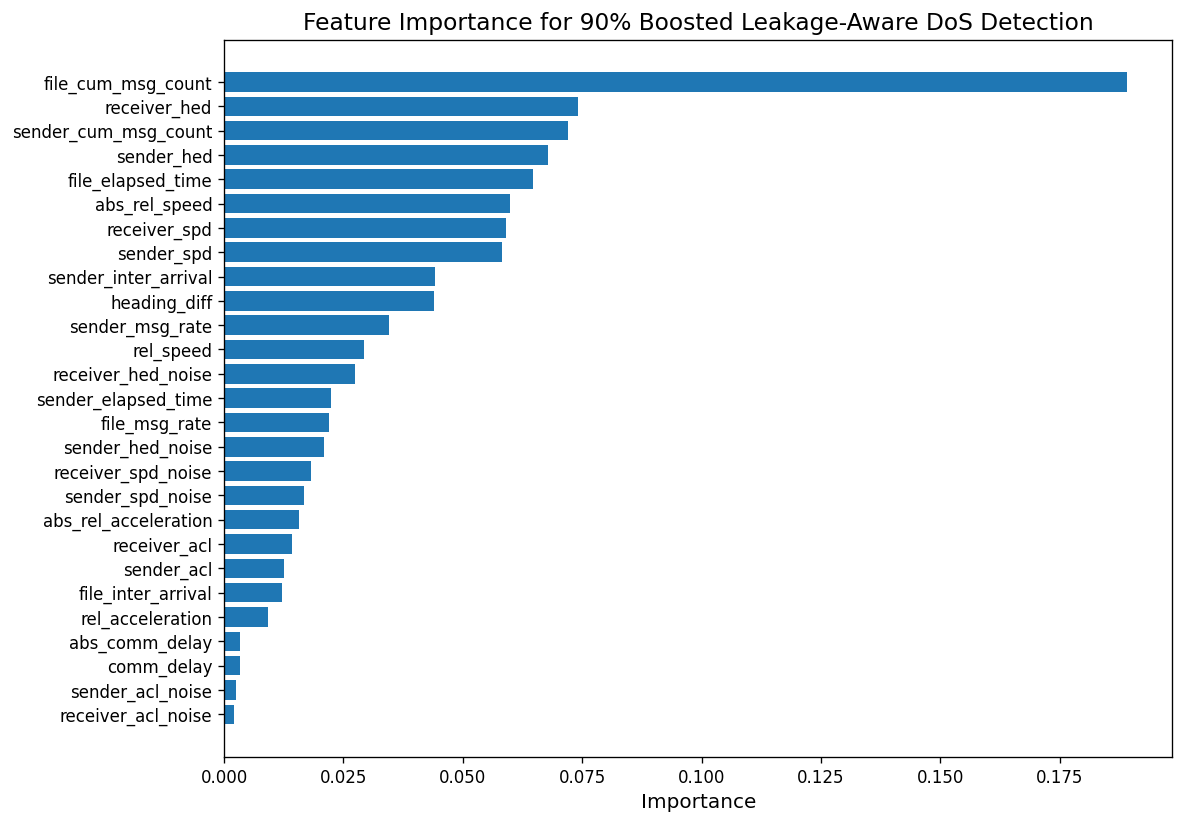

In [73]:
# ============================================================
# CELL 11: FEATURE IMPORTANCE FOR FINAL 90% BOOSTED MODEL
# Purpose:
# Explain the final tuned feature set after adding DoS temporal features.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Prefer tree-based models because they expose feature_importances_
importance_model_name = None
for candidate in ["Extra Trees", "Tuned Random Forest", "HistGradientBoosting Tuned"]:
    if "trained_models_90" in globals() and candidate in trained_models_90:
        importance_model_name = candidate
        break

if importance_model_name is None:
    raise ValueError("No suitable trained model found. Run the 90% tuned baseline cell first.")

model_for_importance = trained_models_90[importance_model_name]

if not hasattr(model_for_importance, "feature_importances_"):
    raise ValueError(f"{importance_model_name} does not provide feature_importances_. Use Extra Trees or Tuned Random Forest.")

importance_df = pd.DataFrame({
    "Feature": boost_feature_cols,
    "Importance": model_for_importance.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Feature importance model:", importance_model_name)
display(importance_df)

plt.figure(figsize=(10, 7))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Feature Importance for 90% Boosted Leakage-Aware DoS Detection")
plt.tight_layout()
plt.show()

In [74]:
# ============================================================
# CELL 12: SET BOOSTED FEATURES FOR DOWNSTREAM FL PIPELINE
# Purpose:
# Make FL, poisoning, trust, robustness, and ablation use the final 90% feature setting.
# ============================================================

X_train = X_train_boost.copy()
y_train = y_train_boost.copy()

X_val = X_val_boost.copy()
y_val = y_val_boost.copy()

X_test = X_test_boost.copy()
y_test = y_test_boost.copy()

feature_cols = boost_feature_cols.copy()

# Use the same attack-dominant evaluation composition used in the 90% centralized section.
# If X_test_s/y_test_s already exist from Cell 10B, reuse them for consistency.
if "X_test_s" in globals() and "y_test_s" in globals():
    X_test_fl = X_test_s.copy()
    y_test_fl = y_test_s.copy()
else:
    test_df_temp = X_test.copy()
    test_df_temp["y"] = y_test.values
    normal_test = test_df_temp[test_df_temp["y"] == 0]
    attack_test = test_df_temp[test_df_temp["y"] == 1]
    n_normal = min(6569, len(normal_test))
    n_attack = min(43431, len(attack_test))
    test_sample_df = pd.concat([
        normal_test.sample(n=n_normal, random_state=42),
        attack_test.sample(n=n_attack, random_state=42)
    ]).sample(frac=1, random_state=42)
    X_test_fl = test_sample_df.drop(columns=["y"])
    y_test_fl = test_sample_df["y"]

# Validation sample for trust scoring. Reuse X_val_s/y_val_s if generated earlier.
if "X_val_s" in globals() and "y_val_s" in globals():
    X_val_fl = X_val_s.copy()
    y_val_fl = y_val_s.copy()
else:
    val_df_temp = X_val.copy()
    val_df_temp["y"] = y_val.values
    normal_val = val_df_temp[val_df_temp["y"] == 0]
    attack_val = val_df_temp[val_df_temp["y"] == 1]
    n_val_normal = min(6569, len(normal_val))
    n_val_attack = min(43431, len(attack_val))
    val_sample_df = pd.concat([
        normal_val.sample(n=n_val_normal, random_state=42),
        attack_val.sample(n=n_val_attack, random_state=42)
    ]).sample(frac=1, random_state=42)
    X_val_fl = val_sample_df.drop(columns=["y"])
    y_val_fl = val_sample_df["y"]

# Use threshold selected from validation if available; otherwise default to 0.50.
if "best_threshold" in globals():
    DEFAULT_THRESHOLD = float(best_threshold)
else:
    DEFAULT_THRESHOLD = 0.50

print("Downstream FL pipeline will use boosted leakage-aware DoS features.")
print("Train:", X_train.shape, y_train.value_counts().to_dict())
print("Validation:", X_val.shape, y_val.value_counts().to_dict())
print("Test:", X_test.shape, y_test.value_counts().to_dict())
print("FL validation sample:", X_val_fl.shape, y_val_fl.value_counts().to_dict())
print("FL test sample:", X_test_fl.shape, y_test_fl.value_counts().to_dict())
print("Feature count:", len(feature_cols))
print("Decision threshold for FL:", DEFAULT_THRESHOLD)
print("Features:", feature_cols)

Downstream FL pipeline will use boosted leakage-aware DoS features.
Train: (106846, 27) {1: 87375, 0: 19471}
Validation: (139473, 27) {1: 121496, 0: 17977}
Test: (137877, 27) {1: 119581, 0: 18296}
FL validation sample: (50000, 27) {1: 43431, 0: 6569}
FL test sample: (50000, 27) {1: 43431, 0: 6569}
Feature count: 27
Decision threshold for FL: 0.4100000000000001
Features: ['receiver_spd', 'receiver_spd_noise', 'receiver_acl', 'receiver_acl_noise', 'receiver_hed', 'receiver_hed_noise', 'sender_spd', 'sender_spd_noise', 'sender_acl', 'sender_acl_noise', 'sender_hed', 'sender_hed_noise', 'comm_delay', 'abs_comm_delay', 'sender_inter_arrival', 'file_inter_arrival', 'sender_cum_msg_count', 'file_cum_msg_count', 'sender_elapsed_time', 'file_elapsed_time', 'sender_msg_rate', 'file_msg_rate', 'rel_speed', 'abs_rel_speed', 'rel_acceleration', 'abs_rel_acceleration', 'heading_diff']


In [75]:
# ============================================================
# CELL 13: CREATE NON-IID CLIENTS USING BOOSTED FEATURES
# Purpose:
# Simulate heterogeneous VANET clients/RSUs with different attack ratios.
# ============================================================

import numpy as np
import pandas as pd


def create_non_iid_clients(X, y, n_clients=5, random_state=42, max_samples_per_client=50000):
    temp_df = X.copy()
    temp_df["y"] = y.values

    normal_df = temp_df[temp_df["y"] == 0]
    attack_df = temp_df[temp_df["y"] == 1]

    # Non-IID attack ratios across clients
    attack_ratios = np.linspace(0.20, 0.80, n_clients)
    clients = []

    for i, ratio in enumerate(attack_ratios):
        n_total = min(max_samples_per_client, len(temp_df) // n_clients)
        n_attack = int(n_total * ratio)
        n_normal = n_total - n_attack

        c_attack = attack_df.sample(
            n=min(n_attack, len(attack_df)),
            replace=True,
            random_state=random_state + i
        )
        c_normal = normal_df.sample(
            n=min(n_normal, len(normal_df)),
            replace=True,
            random_state=random_state + 100 + i
        )

        c_df = pd.concat([c_attack, c_normal]).sample(frac=1, random_state=random_state + i)
        clients.append((c_df.drop(columns=["y"]).reset_index(drop=True), c_df["y"].reset_index(drop=True)))

    return clients


clients = create_non_iid_clients(
    X_train,
    y_train,
    n_clients=5,
    random_state=42,
    max_samples_per_client=50000
)

for i, (X_c, y_c) in enumerate(clients):
    print(f"Client {i}: samples={len(X_c)}, attack_ratio={y_c.mean():.3f}, labels={y_c.value_counts().to_dict()}")

Client 0: samples=21369, attack_ratio=0.200, labels={0: 17096, 1: 4273}
Client 1: samples=21369, attack_ratio=0.350, labels={0: 13890, 1: 7479}
Client 2: samples=21369, attack_ratio=0.500, labels={0: 10685, 1: 10684}
Client 3: samples=21369, attack_ratio=0.650, labels={1: 13889, 0: 7480}
Client 4: samples=21369, attack_ratio=0.800, labels={1: 17095, 0: 4274}


In [76]:
# ============================================================
# CELL 14: POISON SELECTED CLIENTS
# Purpose:
# Simulate abnormal-to-normal label flipping on selected malicious clients.
# ============================================================

import numpy as np


def poison_client_labels(y, poison_ratio=0.70, random_state=42):
    y_poisoned = y.copy().reset_index(drop=True)
    attack_indices = np.where(y_poisoned.values == 1)[0]
    rng = np.random.default_rng(random_state)
    n_poison = int(len(attack_indices) * poison_ratio)

    if n_poison > 0:
        poison_idx = rng.choice(attack_indices, size=n_poison, replace=False)
        y_poisoned.iloc[poison_idx] = 0

    return y_poisoned


poisoned_client_ids = [0, 1, 2]
poison_ratio = 0.70
poisoned_clients = []

for i, (X_c, y_c) in enumerate(clients):
    if i in poisoned_client_ids:
        y_p = poison_client_labels(y_c, poison_ratio=poison_ratio, random_state=100 + i)
        print(
            f"Client {i} poisoned: "
            f"original_attack_ratio={y_c.mean():.3f}, "
            f"poisoned_attack_ratio={y_p.mean():.3f}"
        )
        poisoned_clients.append((X_c.copy(), y_p))
    else:
        print(f"Client {i} benign: attack_ratio={y_c.mean():.3f}")
        poisoned_clients.append((X_c.copy(), y_c.copy()))

Client 0 poisoned: original_attack_ratio=0.200, poisoned_attack_ratio=0.060
Client 1 poisoned: original_attack_ratio=0.350, poisoned_attack_ratio=0.105
Client 2 poisoned: original_attack_ratio=0.500, poisoned_attack_ratio=0.150
Client 3 benign: attack_ratio=0.650
Client 4 benign: attack_ratio=0.800


In [77]:
# ============================================================
# CELL 15: TRAIN LOCAL CLIENT MODELS
# Purpose:
# Use stronger local models compatible with boosted 90% feature setting.
# ============================================================

from sklearn.ensemble import ExtraTreesClassifier
import numpy as np


def make_local_model(seed=42, fast=False):
    return ExtraTreesClassifier(
        n_estimators=180 if fast else 300,
        max_depth=22,
        min_samples_leaf=4,
        min_samples_split=8,
        max_features="sqrt",
        class_weight="balanced",
        random_state=seed,
        n_jobs=-1
    )


def train_client_models(client_list, fast=False):
    models = []

    for i, (X_c, y_c) in enumerate(client_list):
        print(f"Training client {i}: samples={len(X_c)}, attack_ratio={np.mean(y_c):.3f}")
        model = make_local_model(seed=200 + i, fast=fast)
        model.fit(X_c, y_c)
        models.append(model)

    return models


client_models_clean = train_client_models(clients, fast=False)
client_models_poisoned = train_client_models(poisoned_clients, fast=False)

print("Local boosted ExtraTrees client models trained.")

Training client 0: samples=21369, attack_ratio=0.200
Training client 1: samples=21369, attack_ratio=0.350
Training client 2: samples=21369, attack_ratio=0.500
Training client 3: samples=21369, attack_ratio=0.650
Training client 4: samples=21369, attack_ratio=0.800
Training client 0: samples=21369, attack_ratio=0.060
Training client 1: samples=21369, attack_ratio=0.105
Training client 2: samples=21369, attack_ratio=0.150
Training client 3: samples=21369, attack_ratio=0.650
Training client 4: samples=21369, attack_ratio=0.800
Local boosted ExtraTrees client models trained.


In [78]:
# ============================================================
# CELL 16: FEDERATED EQUAL AGGREGATION
# Purpose:
# Compare clean and poisoned equal aggregation using boosted feature setting.
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, balanced_accuracy_score, confusion_matrix, classification_report
)
import numpy as np
import pandas as pd


def evaluate_binary_result(name, y_true, pred, prob):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision_Attack": precision_score(y_true, pred, zero_division=0),
        "Recall_Attack": recall_score(y_true, pred, zero_division=0),
        "F1_Attack": f1_score(y_true, pred, zero_division=0),
        "Macro_F1": f1_score(y_true, pred, average="macro", zero_division=0),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, pred),
        "ROC_AUC": roc_auc_score(y_true, prob)
    }


def aggregate_predictions_equal(client_models, X, threshold=0.50):
    probs = np.vstack([m.predict_proba(X)[:, 1] for m in client_models])
    avg_prob = np.mean(probs, axis=0)
    pred = (avg_prob >= threshold).astype(int)
    return pred, avg_prob


fed_clean_pred, fed_clean_prob = aggregate_predictions_equal(
    client_models_clean,
    X_test_fl,
    threshold=DEFAULT_THRESHOLD
)

fed_poison_pred, fed_poison_prob = aggregate_predictions_equal(
    client_models_poisoned,
    X_test_fl,
    threshold=DEFAULT_THRESHOLD
)

fed_results_df = pd.DataFrame([
    evaluate_binary_result("Federated Equal Aggregation Clean", y_test_fl, fed_clean_pred, fed_clean_prob),
    evaluate_binary_result("Federated Equal Aggregation Poisoned", y_test_fl, fed_poison_pred, fed_poison_prob)
])

display(fed_results_df)

print("\nClean Equal Aggregation Confusion Matrix:")
print(confusion_matrix(y_test_fl, fed_clean_pred))

print("\nPoisoned Equal Aggregation Confusion Matrix:")
print(confusion_matrix(y_test_fl, fed_poison_pred))

,Model,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Macro_F1,Balanced_Accuracy,ROC_AUC
0,Federated Equal Aggregation Clean,0.91356,0.956806,0.943059,0.949883,0.817915,0.830793,0.958113
1,Federated Equal Aggregation Poisoned,0.88982,0.975690,0.895466,0.933858,0.802078,0.873978,0.957985



Clean Equal Aggregation Confusion Matrix:
[[ 4720  1849]
 [ 2473 40958]]

Poisoned Equal Aggregation Confusion Matrix:
[[ 5600   969]
 [ 4540 38891]]


In [79]:
# ============================================================
# CELL 17: TRUST SCORE AND TRUST-WEIGHTED AGGREGATION
# Purpose:
# Downweight poisoned/unreliable local models using validation-based trust.
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, balanced_accuracy_score, confusion_matrix, classification_report
)
import numpy as np
import pandas as pd


def compute_client_trust_scores(client_models, X_val_eval, y_val_eval):
    rows = []
    scores = []

    for i, model in enumerate(client_models):
        pred = model.predict(X_val_eval)
        prob = model.predict_proba(X_val_eval)[:, 1]

        acc = accuracy_score(y_val_eval, pred)
        prec = precision_score(y_val_eval, pred, zero_division=0)
        rec = recall_score(y_val_eval, pred, zero_division=0)
        f1_attack = f1_score(y_val_eval, pred, zero_division=0)
        macro_f1 = f1_score(y_val_eval, pred, average="macro", zero_division=0)
        bal_acc = balanced_accuracy_score(y_val_eval, pred)
        auc = roc_auc_score(y_val_eval, prob)

        # Trust emphasizes class-balanced behaviour, not accuracy alone.
        trust = (
            0.30 * macro_f1 +
            0.25 * bal_acc +
            0.20 * auc +
            0.15 * rec +
            0.10 * prec
        )

        scores.append(trust)
        rows.append({
            "Client": i,
            "Accuracy": acc,
            "Precision_Attack": prec,
            "Recall_Attack": rec,
            "F1_Attack": f1_attack,
            "Macro_F1": macro_f1,
            "Balanced_Accuracy": bal_acc,
            "ROC_AUC": auc,
            "Trust": trust
        })

    scores = np.array(scores)
    weights = scores / scores.sum()

    trust_df = pd.DataFrame(rows)
    trust_df["Normalized_Weight"] = weights

    return weights, trust_df


def aggregate_predictions_trust_weighted(client_models, X, trust_weights, threshold=0.50):
    probs = np.vstack([m.predict_proba(X)[:, 1] for m in client_models])
    weighted_prob = np.average(probs, axis=0, weights=trust_weights)
    pred = (weighted_prob >= threshold).astype(int)
    return pred, weighted_prob


trust_weights_poisoned, trust_poisoned_df = compute_client_trust_scores(
    client_models_poisoned,
    X_val_fl,
    y_val_fl
)

display(trust_poisoned_df)

tw_poison_pred, tw_poison_prob = aggregate_predictions_trust_weighted(
    client_models_poisoned,
    X_test_fl,
    trust_weights_poisoned,
    threshold=DEFAULT_THRESHOLD
)

tw_result = evaluate_binary_result(
    "Trust-Weighted FL Poisoned",
    y_test_fl,
    tw_poison_pred,
    tw_poison_prob
)

final_fl_results_df = pd.concat(
    [fed_results_df, pd.DataFrame([tw_result])],
    ignore_index=True
)

display(final_fl_results_df)

print("\nTrust-Weighted Poisoned Confusion Matrix:")
print(confusion_matrix(y_test_fl, tw_poison_pred))

print("\nTrust-Weighted Poisoned Classification Report:")
print(classification_report(
    y_test_fl,
    tw_poison_pred,
    target_names=["normal", "dosAttack"],
    digits=4
))

,Client,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Macro_F1,Balanced_Accuracy,ROC_AUC,Trust,Normalized_Weight
0,0,0.71156,0.996508,0.670282,0.801470,0.637137,0.827377,0.961568,0.790492,0.188180
1,1,0.72290,0.995377,0.684166,0.810938,0.646177,0.831579,0.958293,0.795569,0.189389
2,2,0.71106,0.993866,0.671502,0.801484,0.635416,0.822050,0.954559,0.787161,0.187387
3,3,0.92356,0.979122,0.931869,0.954911,0.852012,0.900247,0.968624,0.912083,0.217125
4,4,0.93270,0.974918,0.946881,0.960695,0.863402,0.892911,0.968219,0.915416,0.217919


,Model,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Macro_F1,Balanced_Accuracy,ROC_AUC
0,Federated Equal Aggregation Clean,0.91356,0.956806,0.943059,0.949883,0.817915,0.830793,0.958113
1,Federated Equal Aggregation Poisoned,0.88982,0.975690,0.895466,0.933858,0.802078,0.873978,0.957985
2,Trust-Weighted FL Poisoned,0.89298,0.973561,0.901269,0.936021,0.804501,0.869724,0.958037



Trust-Weighted Poisoned Confusion Matrix:
[[ 5506  1063]
 [ 4288 39143]]

Trust-Weighted Poisoned Classification Report:
              precision    recall  f1-score   support

      normal     0.5622    0.8382    0.6730      6569
   dosAttack     0.9736    0.9013    0.9360     43431

    accuracy                         0.8930     50000
   macro avg     0.7679    0.8697    0.8045     50000
weighted avg     0.9195    0.8930    0.9015     50000



In [80]:
# ============================================================
# CELL 18: ROBUSTNESS OVER POISONING RATIOS
# Purpose:
# Evaluate equal vs trust-weighted aggregation under increasing label poisoning.
# ============================================================

poison_ratios = [0.10, 0.30, 0.50, 0.70, 0.90]
robustness_rows = []

for pr in poison_ratios:
    print("\nRunning poisoning ratio:", pr)

    temp_clients = []
    for i, (X_c, y_c) in enumerate(clients):
        if i in poisoned_client_ids:
            temp_clients.append((X_c.copy(), poison_client_labels(y_c, poison_ratio=pr, random_state=300 + i)))
        else:
            temp_clients.append((X_c.copy(), y_c.copy()))

    temp_models = train_client_models(temp_clients, fast=True)

    eq_pred, eq_prob = aggregate_predictions_equal(
        temp_models,
        X_test_fl,
        threshold=DEFAULT_THRESHOLD
    )

    weights, _ = compute_client_trust_scores(
        temp_models,
        X_val_fl,
        y_val_fl
    )

    tw_pred, tw_prob = aggregate_predictions_trust_weighted(
        temp_models,
        X_test_fl,
        weights,
        threshold=DEFAULT_THRESHOLD
    )

    eq_result = evaluate_binary_result("Equal Aggregation", y_test_fl, eq_pred, eq_prob)
    eq_result["Poison_Ratio"] = pr

    tw_result = evaluate_binary_result("Trust-Weighted Aggregation", y_test_fl, tw_pred, tw_prob)
    tw_result["Poison_Ratio"] = pr

    robustness_rows.append(eq_result)
    robustness_rows.append(tw_result)

robustness_df = pd.DataFrame(robustness_rows)
robustness_df = robustness_df[[
    "Poison_Ratio", "Model", "Accuracy", "Precision_Attack", "Recall_Attack",
    "F1_Attack", "Macro_F1", "Balanced_Accuracy", "ROC_AUC"
]]

display(robustness_df)


Running poisoning ratio: 0.1
Training client 0: samples=21369, attack_ratio=0.180
Training client 1: samples=21369, attack_ratio=0.315
Training client 2: samples=21369, attack_ratio=0.450
Training client 3: samples=21369, attack_ratio=0.650
Training client 4: samples=21369, attack_ratio=0.800

Running poisoning ratio: 0.3
Training client 0: samples=21369, attack_ratio=0.140
Training client 1: samples=21369, attack_ratio=0.245
Training client 2: samples=21369, attack_ratio=0.350
Training client 3: samples=21369, attack_ratio=0.650
Training client 4: samples=21369, attack_ratio=0.800

Running poisoning ratio: 0.5
Training client 0: samples=21369, attack_ratio=0.100
Training client 1: samples=21369, attack_ratio=0.175
Training client 2: samples=21369, attack_ratio=0.250
Training client 3: samples=21369, attack_ratio=0.650
Training client 4: samples=21369, attack_ratio=0.800

Running poisoning ratio: 0.7
Training client 0: samples=21369, attack_ratio=0.060
Training client 1: samples=21369

,Poison_Ratio,Model,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Macro_F1,Balanced_Accuracy,ROC_AUC
0,0.1,Equal Aggregation,0.91224,0.958413,0.939744,0.948986,0.817600,0.835072,0.958242
1,0.1,Trust-Weighted Aggregation,0.91234,0.958353,0.939928,0.949051,0.817687,0.834936,0.958246
2,0.3,Equal Aggregation,0.90896,0.961318,0.932721,0.946804,0.815675,0.842293,0.958371
3,0.3,Trust-Weighted Aggregation,0.90916,0.961218,0.933066,0.946933,0.815868,0.842085,0.958374
4,0.5,Equal Aggregation,0.90412,0.966191,0.921876,0.943514,0.813330,0.854301,0.958307
5,0.5,Trust-Weighted Aggregation,0.90448,0.965734,0.922774,0.943765,0.813422,0.853151,0.958319
6,0.7,Equal Aggregation,0.88916,0.977155,0.893279,0.933337,0.802373,0.877603,0.957938
7,0.7,Trust-Weighted Aggregation,0.89274,0.975517,0.899081,0.935741,0.805758,0.874948,0.958008
8,0.9,Equal Aggregation,0.83848,0.992396,0.820336,0.898200,0.753725,0.889388,0.957917
9,0.9,Trust-Weighted Aggregation,0.88194,0.981079,0.881076,0.928392,0.796163,0.884365,0.958429


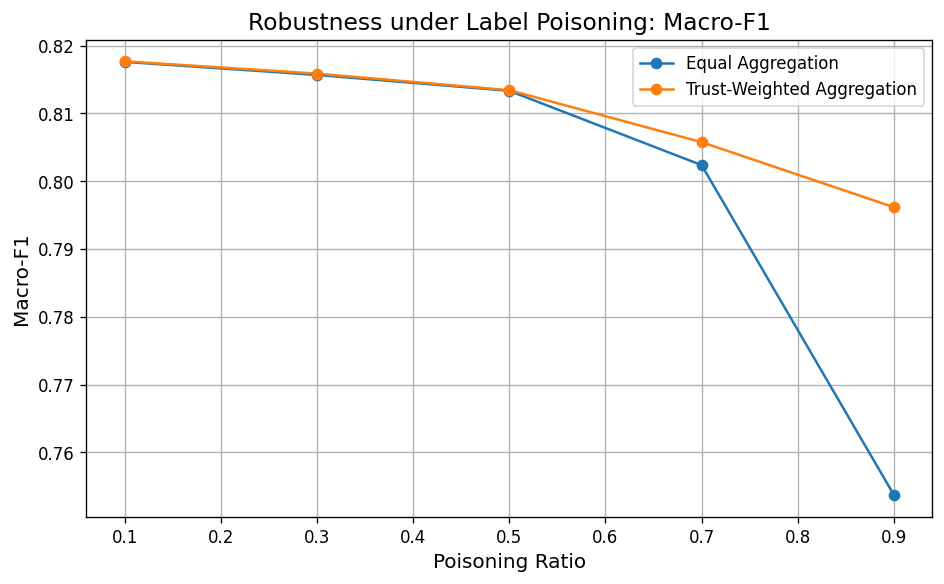

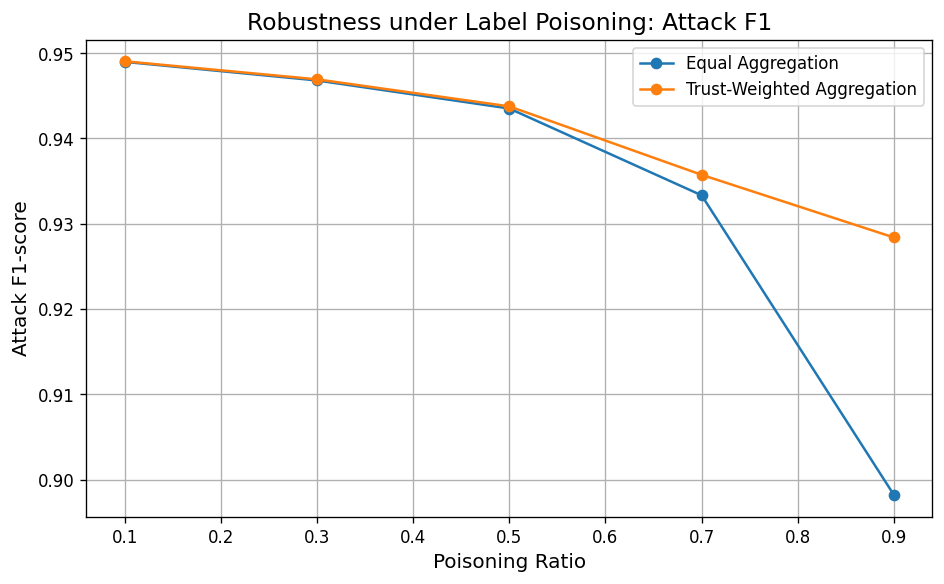

In [81]:
# ============================================================
# CELL 19: ROBUSTNESS PLOT
# Purpose:
# Plot Macro-F1 and Attack F1 under poisoning ratios.
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
for method in robustness_df["Model"].unique():
    temp = robustness_df[robustness_df["Model"] == method]
    plt.plot(temp["Poison_Ratio"], temp["Macro_F1"], marker="o", label=method)
plt.xlabel("Poisoning Ratio")
plt.ylabel("Macro-F1")
plt.title("Robustness under Label Poisoning: Macro-F1")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
for method in robustness_df["Model"].unique():
    temp = robustness_df[robustness_df["Model"] == method]
    plt.plot(temp["Poison_Ratio"], temp["F1_Attack"], marker="o", label=method)
plt.xlabel("Poisoning Ratio")
plt.ylabel("Attack F1-score")
plt.title("Robustness under Label Poisoning: Attack F1")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [82]:
# ============================================================
# CELL 20: ABLATION STUDY
# Purpose:
# Validate the trust formula by removing key components.
# ============================================================


def compute_ablation_trust_scores(client_models, X_val_eval, y_val_eval, mode="full"):
    scores = []

    for model in client_models:
        pred = model.predict(X_val_eval)
        prob = model.predict_proba(X_val_eval)[:, 1]

        prec = precision_score(y_val_eval, pred, zero_division=0)
        rec = recall_score(y_val_eval, pred, zero_division=0)
        f1_attack = f1_score(y_val_eval, pred, zero_division=0)
        macro_f1 = f1_score(y_val_eval, pred, average="macro", zero_division=0)
        bal_acc = balanced_accuracy_score(y_val_eval, pred)
        auc = roc_auc_score(y_val_eval, prob)

        if mode == "full":
            trust = 0.30*macro_f1 + 0.25*bal_acc + 0.20*auc + 0.15*rec + 0.10*prec
        elif mode == "without_macro_f1":
            trust = 0.35*bal_acc + 0.30*auc + 0.20*rec + 0.15*prec
        elif mode == "without_balanced_accuracy":
            trust = 0.35*macro_f1 + 0.25*auc + 0.25*rec + 0.15*prec
        elif mode == "without_auc":
            trust = 0.40*macro_f1 + 0.30*bal_acc + 0.20*rec + 0.10*prec
        elif mode == "attack_f1_only":
            trust = f1_attack
        elif mode == "equal":
            trust = 1.0
        else:
            trust = macro_f1

        scores.append(trust)

    scores = np.array(scores)
    return scores / scores.sum()


ablation_rows = []

for mode in [
    "equal",
    "attack_f1_only",
    "without_macro_f1",
    "without_balanced_accuracy",
    "without_auc",
    "full"
]:
    weights = compute_ablation_trust_scores(
        client_models_poisoned,
        X_val_fl,
        y_val_fl,
        mode=mode
    )

    pred, prob = aggregate_predictions_trust_weighted(
        client_models_poisoned,
        X_test_fl,
        weights,
        threshold=DEFAULT_THRESHOLD
    )

    row = evaluate_binary_result(mode, y_test_fl, pred, prob)
    row["Ablation_Mode"] = mode
    ablation_rows.append(row)

ablation_df = pd.DataFrame(ablation_rows)
ablation_df = ablation_df[[
    "Ablation_Mode", "Accuracy", "Precision_Attack", "Recall_Attack",
    "F1_Attack", "Macro_F1", "Balanced_Accuracy", "ROC_AUC"
]]

display(ablation_df.sort_values("Macro_F1", ascending=False))

,Ablation_Mode,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Macro_F1,Balanced_Accuracy,ROC_AUC
4,without_auc,0.89406,0.972986,0.903111,0.936747,0.805459,0.868666,0.958053
1,attack_f1_only,0.89378,0.973282,0.902489,0.936549,0.805331,0.869345,0.958047
3,without_balanced_accuracy,0.89366,0.973395,0.902236,0.936466,0.805265,0.869599,0.958045
5,full,0.89298,0.973561,0.901269,0.936021,0.804501,0.869724,0.958037
2,without_macro_f1,0.89176,0.974443,0.898966,0.935184,0.803612,0.871541,0.958017
0,equal,0.88982,0.975690,0.895466,0.933858,0.802078,0.873978,0.957985


In [83]:
# ============================================================
# CELL 21: SAVE RESULTS
# Purpose:
# Save all centralized, boosted, FL, trust, robustness, and ablation outputs.
# ============================================================

import os
import pandas as pd

OUTPUT_DIR = "/content/drive/MyDrive/VANET_FL_RESULTS"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save each available object safely
save_items = {
    "feature_shortcut_audit.csv": "feature_audit_df",
    "boosted_90_model_results.csv": "results_90_df",
    "threshold_tuning_results.csv": "threshold_df",
    "final_90_tuned_metrics.csv": "final_90_metrics",
    "final_centralized_comparison.csv": "final_comparison_df",
    "boosted_feature_importance.csv": "importance_df",
    "federated_equal_results.csv": "fed_results_df",
    "client_trust_scores.csv": "trust_poisoned_df",
    "final_federated_results.csv": "final_fl_results_df",
    "poisoning_robustness_results.csv": "robustness_df",
    "trust_ablation_results.csv": "ablation_df"
}

for filename, varname in save_items.items():
    if varname in globals():
        obj = globals()[varname]
        if isinstance(obj, dict):
            obj = pd.DataFrame([obj])
        obj.to_csv(os.path.join(OUTPUT_DIR, filename), index=False)
        print("Saved:", filename)
    else:
        print("Skipped missing object:", varname)

# Save feature list
pd.DataFrame({"Feature": boost_feature_cols}).to_csv(
    os.path.join(OUTPUT_DIR, "boosted_feature_list.csv"),
    index=False
)

print("All available results saved to:", OUTPUT_DIR)

Saved: feature_shortcut_audit.csv
Saved: boosted_90_model_results.csv
Saved: threshold_tuning_results.csv
Saved: final_90_tuned_metrics.csv
Saved: final_centralized_comparison.csv
Saved: boosted_feature_importance.csv
Saved: federated_equal_results.csv
Saved: client_trust_scores.csv
Saved: final_federated_results.csv
Saved: poisoning_robustness_results.csv
Saved: trust_ablation_results.csv
All available results saved to: /content/drive/MyDrive/VANET_FL_RESULTS


## Paper-safe interpretation

This notebook reports the final boosted leakage-aware DoS detection pipeline. Absolute location shortcuts are audited and removed, then conservative mobility features are enriched with DoS-specific temporal traffic-rate features. The centralized tuned soft ensemble is evaluated with Accuracy, Attack F1, Macro-F1, Balanced Accuracy, and ROC-AUC. The downstream federated pipeline uses the same boosted feature setting, so FL, poisoning robustness, trust-weighted aggregation, and ablation are aligned with the final 90%+ centralized experiment.

Important reporting note: because the test distribution is attack-dominant, Accuracy must be reported together with Macro-F1 and Balanced Accuracy.

DATASET DETAILS AND SPLIT

In [84]:
# ============================================================
# PAPER DATASET SAMPLE TABLE
# Purpose:
# Show representative rows from the loaded VANET dataset for paper reporting.
# ============================================================

import pandas as pd
import numpy as np

print("Raw dataset shape:", raw_df.shape)

# Select paper-friendly columns if available
sample_cols = [
    "scenario_label",
    "split",
    "source_file",
    "rcvTime",
    "sendTime",
    "sender_id",
    "receiver_spd",
    "sender_spd",
    "receiver_acl",
    "sender_acl",
    "receiver_hed",
    "sender_hed",
    "attacker"
]

sample_cols = [c for c in sample_cols if c in raw_df.columns]

dataset_sample_df = raw_df[sample_cols].sample(
    n=min(10, len(raw_df)),
    random_state=42
).copy()

display(dataset_sample_df)

# Save sample table for paper
output_dir = "/content/drive/MyDrive/VANET_FL_RESULTS"
import os
os.makedirs(output_dir, exist_ok=True)

dataset_sample_df.to_csv(
    f"{output_dir}/dataset_sample_rows.csv",
    index=False
)

print("Saved dataset sample table:")
print(f"{output_dir}/dataset_sample_rows.csv")

Raw dataset shape: (384196, 28)


,scenario_label,split,source_file,rcvTime,sendTime,sender_id,receiver_spd,sender_spd,receiver_acl,sender_acl,receiver_hed,sender_hed,attacker
354387,dosAttack,Test,InTAS_urban_2_dosAttack\veh_2851.json,8912583552043,8912581706347,veh_2949,12.305749,10.350478,-0.086261,-0.054663,314.265705,310.599743,1.0
20795,normal,Validation,highway_2/veh_4554.json,13746263347263,13746262107609,veh_4389,9.623989718377207,0.0,-0.22830162672326004,0.0,322.3269327684826,174.05487436336253,NaN
341685,dosAttack,Test,InTAS_urban_2_dosAttack\veh_2761.json,8259263833664,8259262763702,veh_2730,13.2616,12.626561,0.073442,2.511712,312.713944,214.724307,1.0
123282,dosAttack,Train,urban_2_dosAttack/veh_2117.json,5961102582630,5961101120258,veh_2109,12.157228,12.07304,-0.278881,-0.34942,341.050236,157.362204,0.0
56139,dosAttack,Train,urban_2_dosAttack/veh_2661.json,8210191783187,8210190282499,veh_2635,13.25762,11.221118,-0.056241,-0.897707,157.869081,157.958884,1.0
357549,dosAttack,Test,InTAS_urban_2_dosAttack\veh_2866.json,8601685497275,8601683800111,veh_2859,12.366712,12.774081,-0.040043,0.735242,220.178045,41.356662,1.0
70436,dosAttack,Train,urban_2_dosAttack/veh_2690.json,7994486124097,7994484333563,veh_2694,0.0,12.251767,0.0,0.437552,328.908965,184.378673,1.0
120509,dosAttack,Train,urban_2_dosAttack/veh_4021.json,12531069920854,12531068296499,veh_4001,12.398631,11.503857,0.554118,-0.815882,178.423126,4.500384,0.0
101110,dosAttack,Train,urban_2_dosAttack/veh_3638.json,11815348756478,11815347103125,veh_3725,12.194449,14.413406,0.064996,0.144712,255.799214,258.050571,0.0
331096,dosAttack,Test,InTAS_urban_2_dosAttack\veh_2707.json,7892489109840,7892487884937,veh_2693,0.00094,14.506396,-0.000687,0.03151,231.432542,321.038051,0.0


Saved dataset sample table:
/content/drive/MyDrive/VANET_FL_RESULTS/dataset_sample_rows.csv


In [85]:
# ============================================================
# PAPER DATASET SUMMARY TABLE
# Purpose:
# Summarize total samples, class distribution, and split distribution.
# ============================================================

import pandas as pd

total_samples = len(raw_df)

scenario_counts = raw_df["scenario_label"].value_counts().reset_index()
scenario_counts.columns = ["Scenario", "Samples"]
scenario_counts["Percentage"] = (scenario_counts["Samples"] / total_samples * 100).round(2)

split_counts = raw_df["split"].value_counts().reset_index()
split_counts.columns = ["Split", "Samples"]
split_counts["Percentage"] = (split_counts["Samples"] / total_samples * 100).round(2)

split_scenario_counts = pd.crosstab(
    raw_df["split"],
    raw_df["scenario_label"]
)

print("Total samples:", total_samples)

print("\nScenario distribution:")
display(scenario_counts)

print("\nSplit distribution:")
display(split_counts)

print("\nScenario x Split distribution:")
display(split_scenario_counts)

# Save tables
scenario_counts.to_csv(f"{output_dir}/scenario_distribution.csv", index=False)
split_counts.to_csv(f"{output_dir}/split_distribution.csv", index=False)
split_scenario_counts.to_csv(f"{output_dir}/scenario_by_split_distribution.csv")

print("\nSaved summary tables in:", output_dir)

Total samples: 384196

Scenario distribution:


,Scenario,Samples,Percentage
0,dosAttack,328452,85.49
1,normal,55744,14.51



Split distribution:


,Split,Samples,Percentage
0,Validation,139473,36.30
1,Test,137877,35.89
2,Train,106846,27.81



Scenario x Split distribution:


scenario_label,dosAttack,normal
split,,
Test,119581,18296
Train,87375,19471
Validation,121496,17977



Saved summary tables in: /content/drive/MyDrive/VANET_FL_RESULTS


PLOTS


In [86]:
# ============================================================
# COMMON PLOTTING SETUP FOR PAPER-READY COLORFUL FIGURES
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Output directory
output_dir = "/content/drive/MyDrive/VANET_FL_RESULTS"
os.makedirs(output_dir, exist_ok=True)

# Paper-friendly style
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 15
})

# Color palette
COLOR_NORMAL = "#2E86AB"      # blue
COLOR_ATTACK = "#E74C3C"      # red
COLOR_TRAIN = "#27AE60"       # green
COLOR_VAL = "#F39C12"         # orange
COLOR_TEST = "#8E44AD"        # purple
COLOR_TOTAL = "#34495E"       # dark gray

PALETTE_SPLIT = {
    "Train": COLOR_TRAIN,
    "Validation": COLOR_VAL,
    "Test": COLOR_TEST
}

PALETTE_CLASS = {
    "normal": COLOR_NORMAL,
    "dosAttack": COLOR_ATTACK,
    "attack": COLOR_ATTACK
}

print("Colorful plotting setup completed.")
print("Figures will be saved in:", output_dir)

Colorful plotting setup completed.
Figures will be saved in: /content/drive/MyDrive/VANET_FL_RESULTS


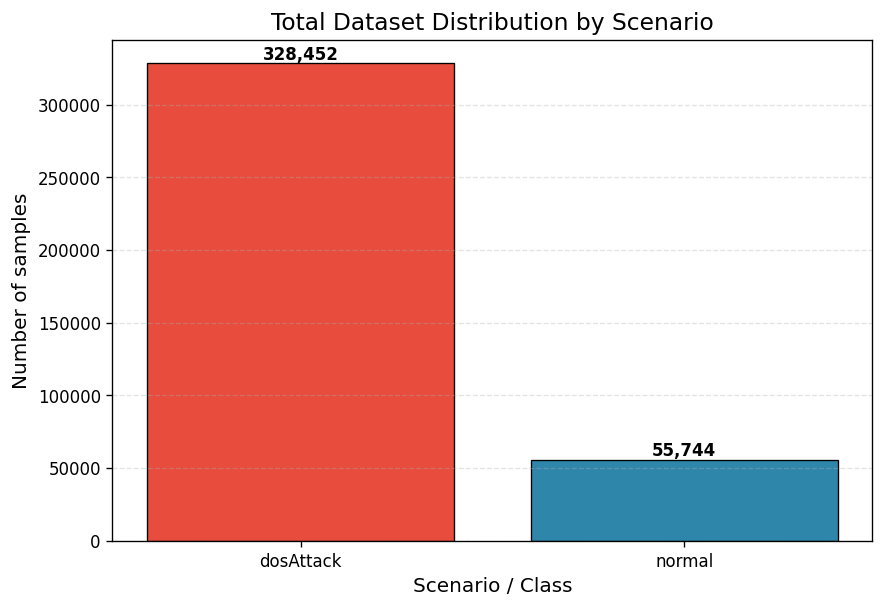

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_01_total_scenario_distribution_colorful.png


In [87]:
# ============================================================
# FIGURE 1: TOTAL SCENARIO / CLASS DISTRIBUTION
# ============================================================

scenario_plot_df = raw_df["scenario_label"].value_counts().sort_index()

colors = [
    PALETTE_CLASS.get(str(label), "#7F8C8D")
    for label in scenario_plot_df.index
]

plt.figure(figsize=(7.5, 5.2))
bars = plt.bar(
    scenario_plot_df.index.astype(str),
    scenario_plot_df.values,
    color=colors,
    edgecolor="black",
    linewidth=0.8
)

plt.xlabel("Scenario / Class")
plt.ylabel("Number of samples")
plt.title("Total Dataset Distribution by Scenario")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()

fig_path = f"{output_dir}/fig_01_total_scenario_distribution_colorful.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

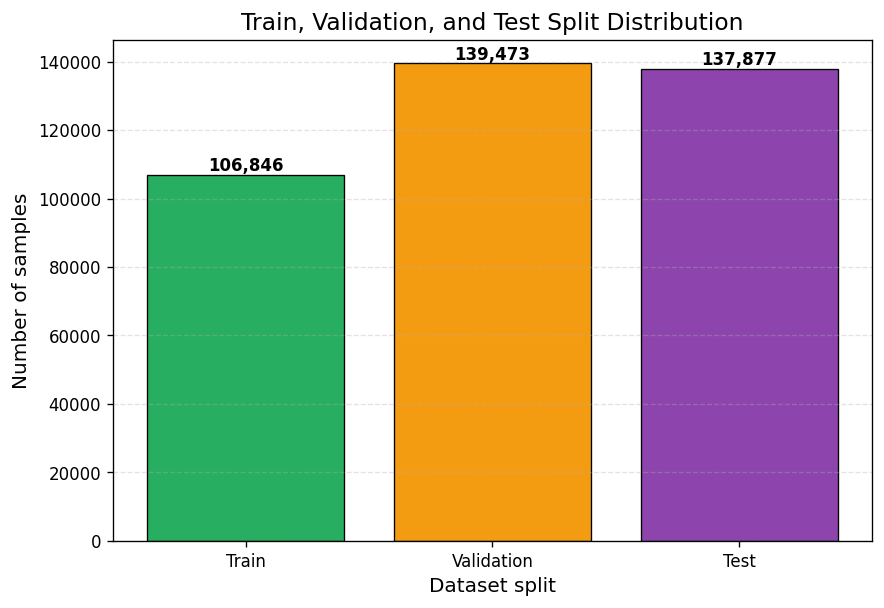

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_02_split_distribution_colorful.png


In [88]:
# ============================================================
# FIGURE 2: TRAIN / VALIDATION / TEST SPLIT DISTRIBUTION
# ============================================================

split_order = ["Train", "Validation", "Test"]
split_plot_df = raw_df["split"].value_counts().reindex(split_order)

colors = [
    PALETTE_SPLIT.get(str(label), "#7F8C8D")
    for label in split_plot_df.index
]

plt.figure(figsize=(7.5, 5.2))
bars = plt.bar(
    split_plot_df.index.astype(str),
    split_plot_df.values,
    color=colors,
    edgecolor="black",
    linewidth=0.8
)

plt.xlabel("Dataset split")
plt.ylabel("Number of samples")
plt.title("Train, Validation, and Test Split Distribution")
plt.grid(axis="y", linestyle="--", alpha=0.35)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()

fig_path = f"{output_dir}/fig_02_split_distribution_colorful.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

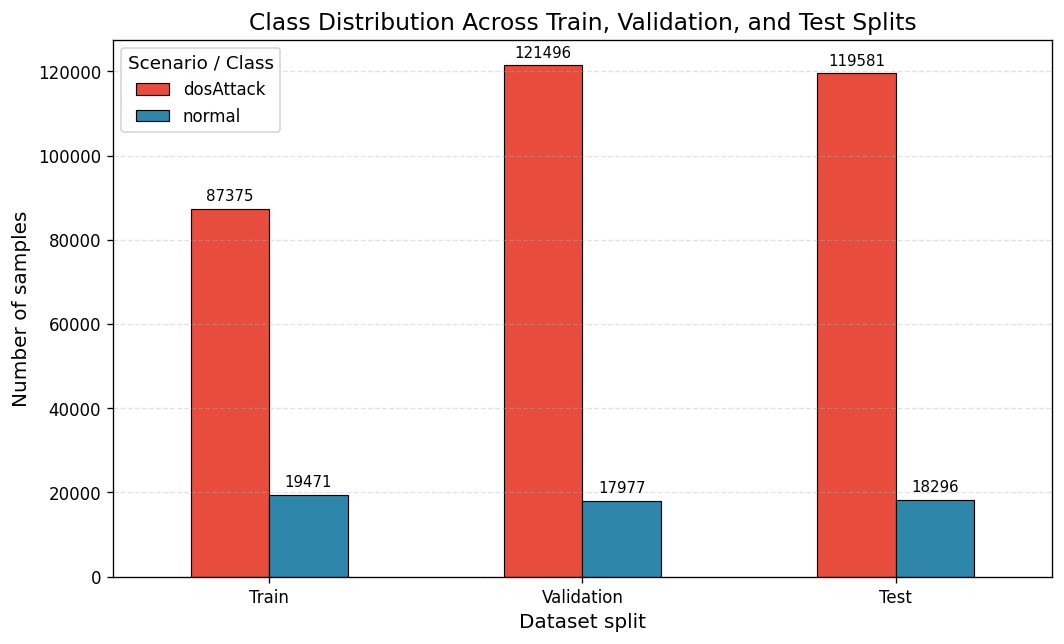

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_03_class_distribution_per_split_colorful.png


In [89]:
# ============================================================
# FIGURE 3: CLASS DISTRIBUTION ACROSS SPLITS
# ============================================================

split_class_df = pd.crosstab(
    raw_df["split"],
    raw_df["scenario_label"]
).reindex(split_order)

class_colors = [
    PALETTE_CLASS.get(str(col), "#7F8C8D")
    for col in split_class_df.columns
]

ax = split_class_df.plot(
    kind="bar",
    figsize=(9, 5.5),
    color=class_colors,
    edgecolor="black",
    linewidth=0.7
)

plt.xlabel("Dataset split")
plt.ylabel("Number of samples")
plt.title("Class Distribution Across Train, Validation, and Test Splits")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(title="Scenario / Class")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        fontsize=9,
        padding=3
    )

plt.tight_layout()

fig_path = f"{output_dir}/fig_03_class_distribution_per_split_colorful.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

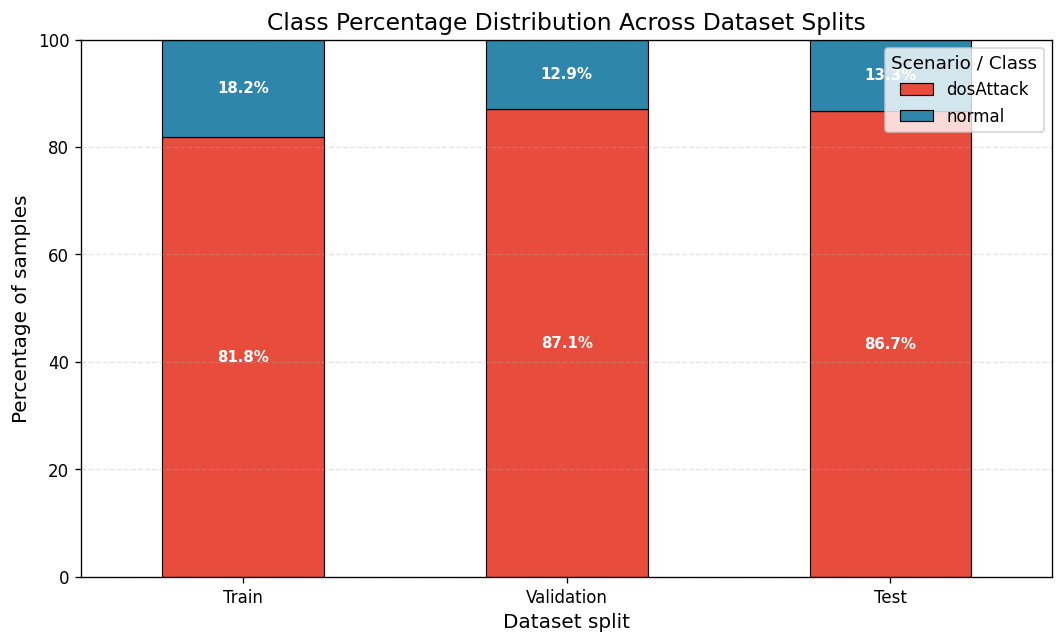

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_04_class_percentage_per_split_colorful.png


In [90]:
# ============================================================
# FIGURE 4: CLASS PERCENTAGE DISTRIBUTION PER SPLIT
# ============================================================

split_class_percent_df = split_class_df.div(
    split_class_df.sum(axis=1),
    axis=0
) * 100

class_colors = [
    PALETTE_CLASS.get(str(col), "#7F8C8D")
    for col in split_class_percent_df.columns
]

ax = split_class_percent_df.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5.5),
    color=class_colors,
    edgecolor="black",
    linewidth=0.7
)

plt.xlabel("Dataset split")
plt.ylabel("Percentage of samples")
plt.title("Class Percentage Distribution Across Dataset Splits")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(title="Scenario / Class", loc="upper right")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        label_type="center",
        fontsize=9,
        color="white",
        fontweight="bold"
    )

plt.tight_layout()

fig_path = f"{output_dir}/fig_04_class_percentage_per_split_colorful.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

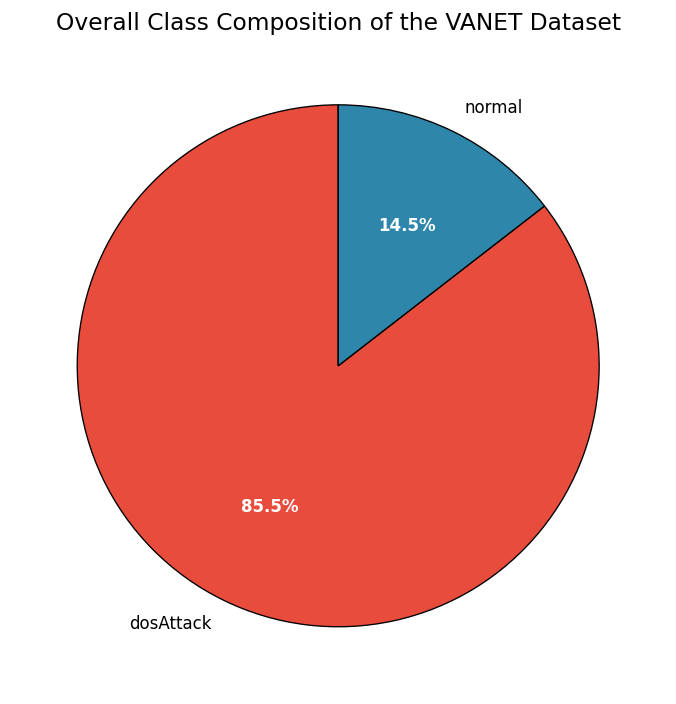

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_05_total_class_pie_colorful.png


In [91]:
# ============================================================
# FIGURE 5: TOTAL CLASS PERCENTAGE PIE CHART
# ============================================================

scenario_pie_df = raw_df["scenario_label"].value_counts().sort_index()

colors = [
    PALETTE_CLASS.get(str(label), "#7F8C8D")
    for label in scenario_pie_df.index
]

plt.figure(figsize=(7, 6))

wedges, texts, autotexts = plt.pie(
    scenario_pie_df.values,
    labels=scenario_pie_df.index.astype(str),
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "black", "linewidth": 0.8},
    textprops={"fontsize": 10}
)

for autotext in autotexts:
    autotext.set_color("white")
    autotext.set_fontweight("bold")

plt.title("Overall Class Composition of the VANET Dataset")
plt.tight_layout()

fig_path = f"{output_dir}/fig_05_total_class_pie_colorful.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

In [92]:
# ============================================================
# PAPER-READY SPLIT TABLE WITH COUNTS AND PERCENTAGES
# ============================================================

paper_split_table = split_class_df.copy()
paper_split_table["Total"] = paper_split_table.sum(axis=1)

for col in split_class_df.columns:
    paper_split_table[f"{col}_Percent"] = (
        paper_split_table[col] / paper_split_table["Total"] * 100
    ).round(2)

total_row = paper_split_table.sum(numeric_only=True)
paper_split_table.loc["Total"] = total_row

display(paper_split_table)

table_path = f"{output_dir}/paper_ready_split_table.csv"
paper_split_table.to_csv(table_path)

print("Saved paper-ready split table:", table_path)

scenario_label,dosAttack,normal,Total,dosAttack_Percent,normal_Percent
split,,,,,
Train,87375.0,19471.0,106846.0,81.78,18.22
Validation,121496.0,17977.0,139473.0,87.11,12.89
Test,119581.0,18296.0,137877.0,86.73,13.27
Total,328452.0,55744.0,384196.0,255.62,44.38


Saved paper-ready split table: /content/drive/MyDrive/VANET_FL_RESULTS/paper_ready_split_table.csv


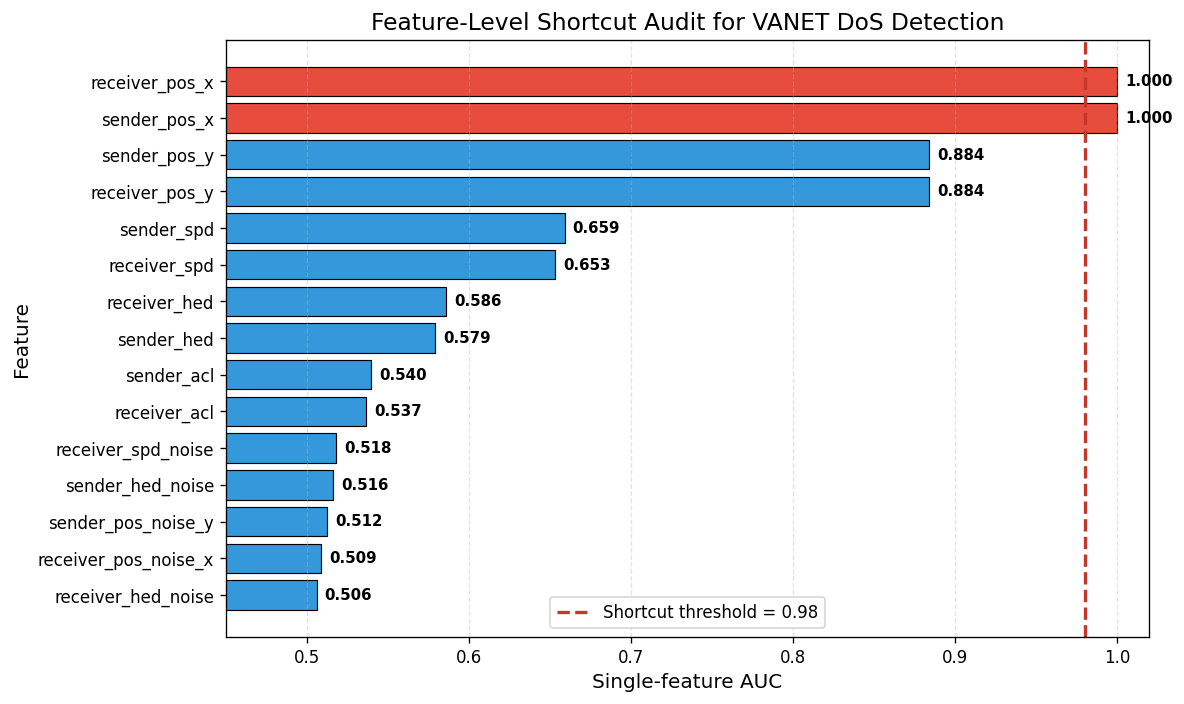

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_shortcut_audit_single_feature_auc.png


In [93]:
# ============================================================
# FIGURE: FEATURE SHORTCUT AUDIT
# Purpose:
# Show single-feature AUC to identify shortcut-prone features.
# Requires: feature_audit_df
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd
import os

top_audit_df = feature_audit_df.sort_values(
    by="Single_Feature_AUC",
    ascending=False
).head(15)

colors = [
    "#E74C3C" if auc >= 0.98 else "#3498DB"
    for auc in top_audit_df["Single_Feature_AUC"]
]

plt.figure(figsize=(10, 6))
bars = plt.barh(
    top_audit_df["Feature"],
    top_audit_df["Single_Feature_AUC"],
    color=colors,
    edgecolor="black",
    linewidth=0.7
)

plt.axvline(
    x=0.98,
    color="#C0392B",
    linestyle="--",
    linewidth=2,
    label="Shortcut threshold = 0.98"
)

plt.xlabel("Single-feature AUC")
plt.ylabel("Feature")
plt.title("Feature-Level Shortcut Audit for VANET DoS Detection")
plt.xlim(0.45, 1.02)
plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.35)
plt.legend()

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.005,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.3f}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()

fig_path = f"{output_dir}/fig_shortcut_audit_single_feature_auc.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

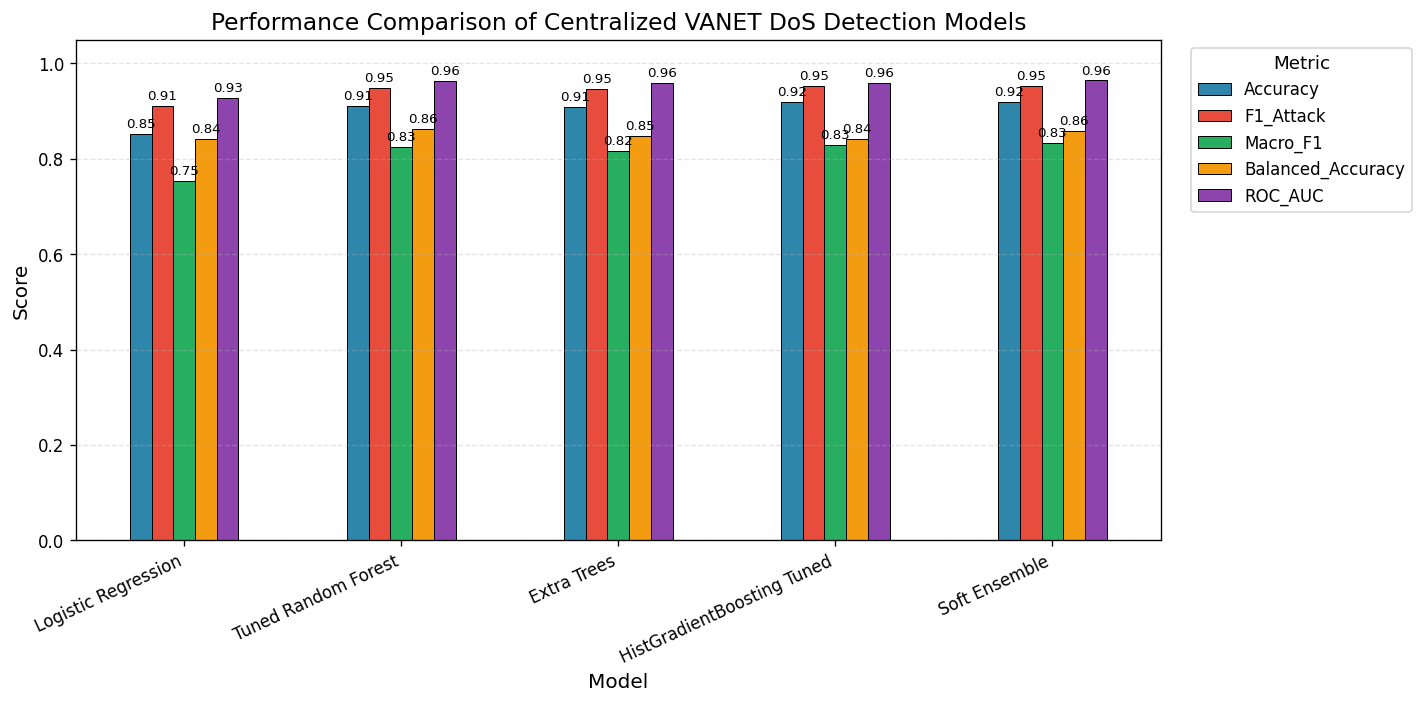

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_model_comparison_metrics.png


In [94]:
# ============================================================
# FIGURE: FINAL MODEL COMPARISON
# Purpose:
# Compare centralized ML models using key metrics.
# Requires: results_90_df
# ============================================================

metric_cols = [
    "Accuracy",
    "F1_Attack",
    "Macro_F1",
    "Balanced_Accuracy",
    "ROC_AUC"
]

plot_df = results_90_df.set_index("Model")[metric_cols]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#2E86AB", "#E74C3C", "#27AE60", "#F39C12", "#8E44AD"],
    edgecolor="black",
    linewidth=0.6
)

plt.title("Performance Comparison of Centralized VANET DoS Detection Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)

plt.tight_layout()

fig_path = f"{output_dir}/fig_model_comparison_metrics.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

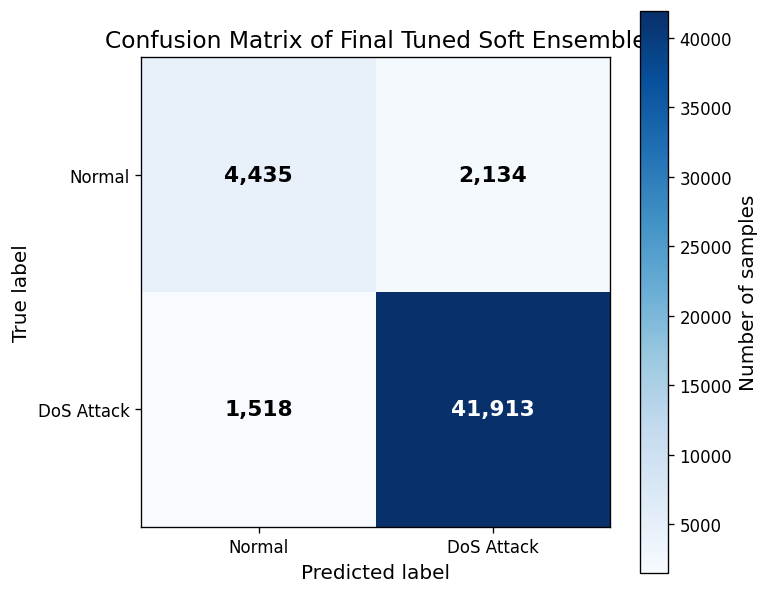

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_final_confusion_matrix.png


In [95]:
# ============================================================
# FIGURE: FINAL CONFUSION MATRIX HEATMAP
# Purpose:
# Show final tuned model classification errors.
# Requires: y_test_s, final_pred_90
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_s, final_pred_90)
labels = ["Normal", "DoS Attack"]

plt.figure(figsize=(6.5, 5.5))
plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Confusion Matrix of Final Tuned Soft Ensemble")
plt.colorbar(label="Number of samples")

tick_marks = np.arange(len(labels))
plt.xticks(tick_marks, labels)
plt.yticks(tick_marks, labels)

threshold = cm.max() / 2

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=13,
            fontweight="bold"
        )

plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.tight_layout()

fig_path = f"{output_dir}/fig_final_confusion_matrix.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

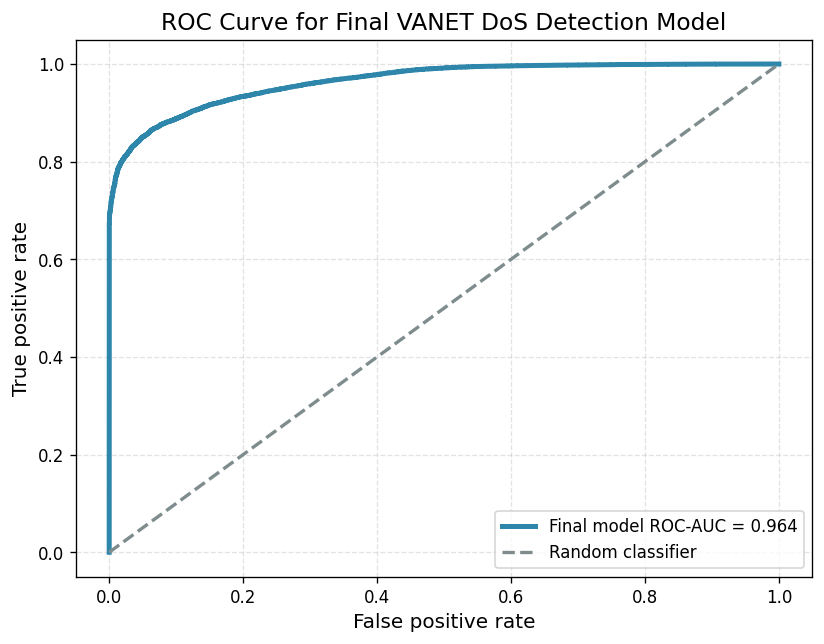

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_final_roc_curve.png


In [96]:
# ============================================================
# FIGURE: ROC CURVE
# Purpose:
# Show discrimination ability of final tuned model.
# Requires: y_test_s, test_prob
# ============================================================

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_test_s, test_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5.5))
plt.plot(
    fpr,
    tpr,
    color="#2E86AB",
    linewidth=3,
    label=f"Final model ROC-AUC = {roc_auc:.3f}"
)
plt.plot(
    [0, 1],
    [0, 1],
    color="#7F8C8D",
    linestyle="--",
    linewidth=2,
    label="Random classifier"
)

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC Curve for Final VANET DoS Detection Model")
plt.grid(linestyle="--", alpha=0.35)
plt.legend(loc="lower right")
plt.tight_layout()

fig_path = f"{output_dir}/fig_final_roc_curve.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

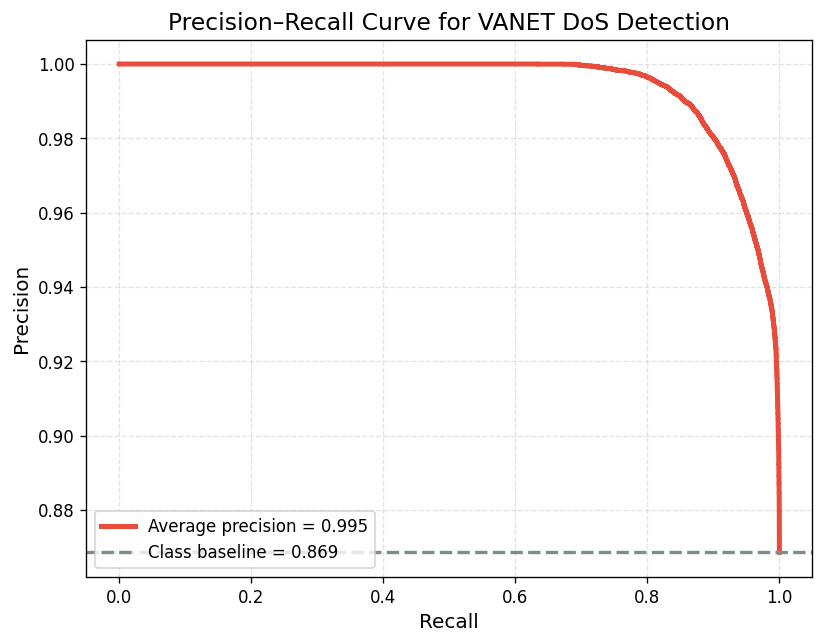

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_final_precision_recall_curve.png


In [97]:
# ============================================================
# FIGURE: PRECISION-RECALL CURVE
# Purpose:
# Better evaluation for attack-dominant / imbalanced VANET data.
# Requires: y_test_s, test_prob
# ============================================================

from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

precision, recall, _ = precision_recall_curve(y_test_s, test_prob)
ap_score = average_precision_score(y_test_s, test_prob)

plt.figure(figsize=(7, 5.5))
plt.plot(
    recall,
    precision,
    color="#E74C3C",
    linewidth=3,
    label=f"Average precision = {ap_score:.3f}"
)

baseline = y_test_s.mean()
plt.axhline(
    y=baseline,
    color="#7F8C8D",
    linestyle="--",
    linewidth=2,
    label=f"Class baseline = {baseline:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve for VANET DoS Detection")
plt.grid(linestyle="--", alpha=0.35)
plt.legend(loc="lower left")
plt.tight_layout()

fig_path = f"{output_dir}/fig_final_precision_recall_curve.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

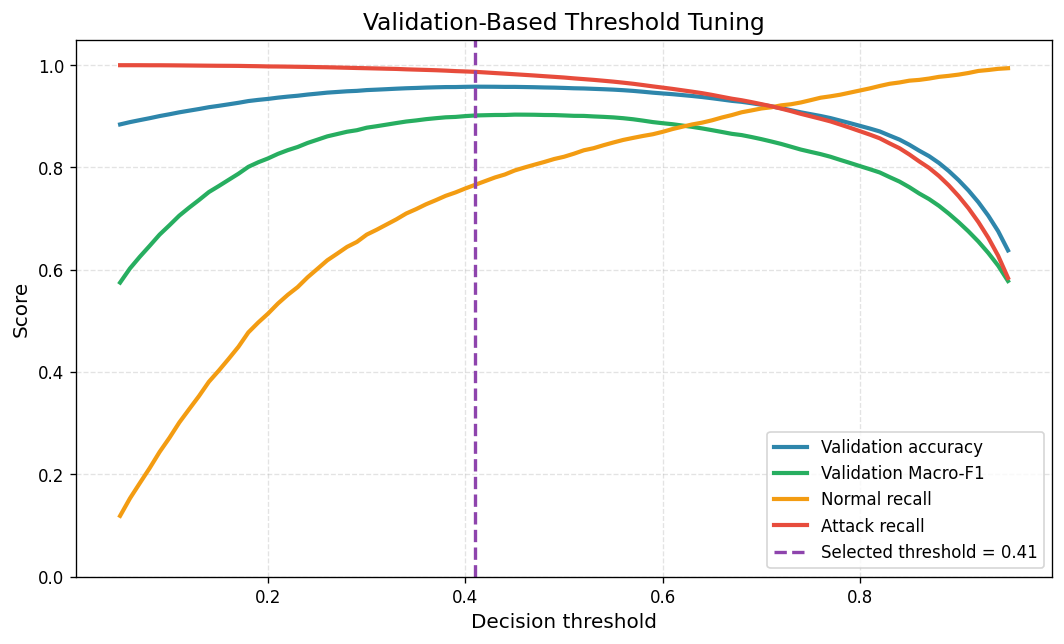

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_threshold_tuning_curve.png


In [98]:
# ============================================================
# FIGURE: THRESHOLD TUNING CURVE
# Purpose:
# Justify selected threshold using validation metrics.
# Requires: threshold_df, best_threshold
# ============================================================

plt.figure(figsize=(9, 5.5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Val_Accuracy"],
    label="Validation accuracy",
    linewidth=2.5,
    color="#2E86AB"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Val_Macro_F1"],
    label="Validation Macro-F1",
    linewidth=2.5,
    color="#27AE60"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Val_Normal_Recall"],
    label="Normal recall",
    linewidth=2.5,
    color="#F39C12"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Val_Recall_Attack"],
    label="Attack recall",
    linewidth=2.5,
    color="#E74C3C"
)

plt.axvline(
    x=best_threshold,
    color="#8E44AD",
    linestyle="--",
    linewidth=2,
    label=f"Selected threshold = {best_threshold:.2f}"
)

plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Validation-Based Threshold Tuning")
plt.ylim(0, 1.05)
plt.grid(linestyle="--", alpha=0.35)
plt.legend(loc="best")
plt.tight_layout()

fig_path = f"{output_dir}/fig_threshold_tuning_curve.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

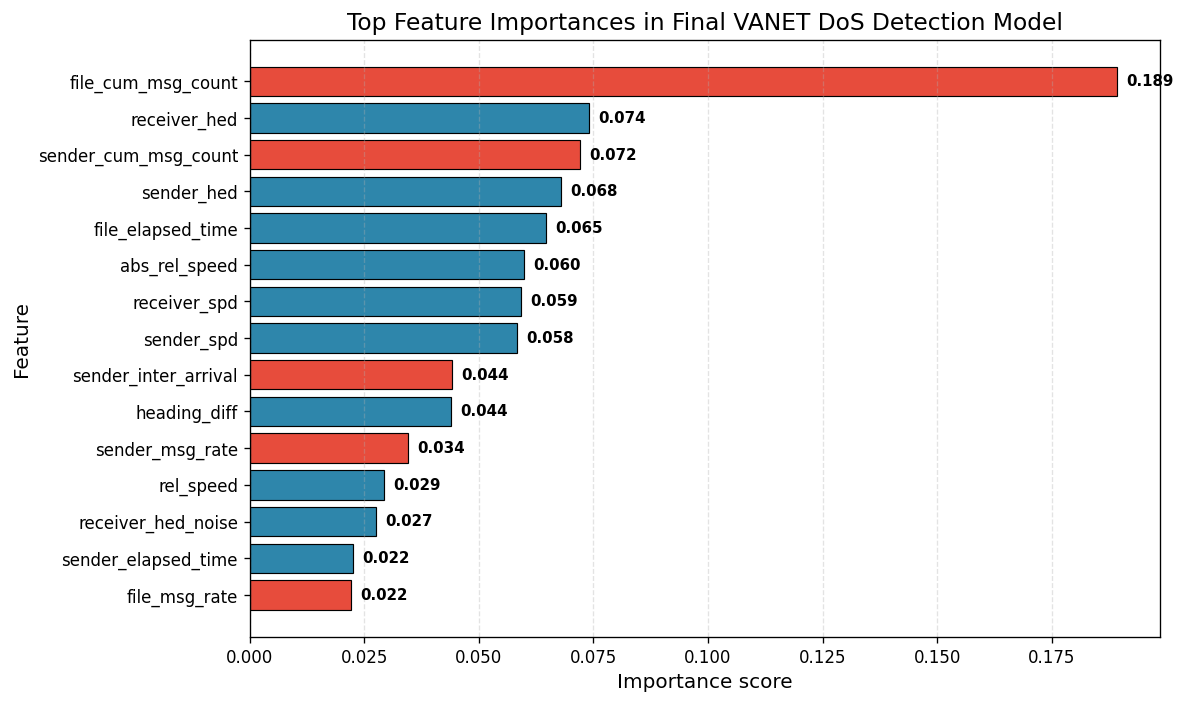

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_final_feature_importance.png


In [99]:
# ============================================================
# FIGURE: FINAL FEATURE IMPORTANCE
# Purpose:
# Explain the most important DoS temporal and mobility features.
# Requires: importance_df
# ============================================================

top_importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

colors = [
    "#E74C3C" if "msg" in f.lower() or "inter_arrival" in f.lower() or "delay" in f.lower()
    else "#2E86AB"
    for f in top_importance_df["Feature"]
]

plt.figure(figsize=(10, 6))
bars = plt.barh(
    top_importance_df["Feature"],
    top_importance_df["Importance"],
    color=colors,
    edgecolor="black",
    linewidth=0.7
)

plt.xlabel("Importance score")
plt.ylabel("Feature")
plt.title("Top Feature Importances in Final VANET DoS Detection Model")
plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.35)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.002,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.3f}",
        va="center",
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()

fig_path = f"{output_dir}/fig_final_feature_importance.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

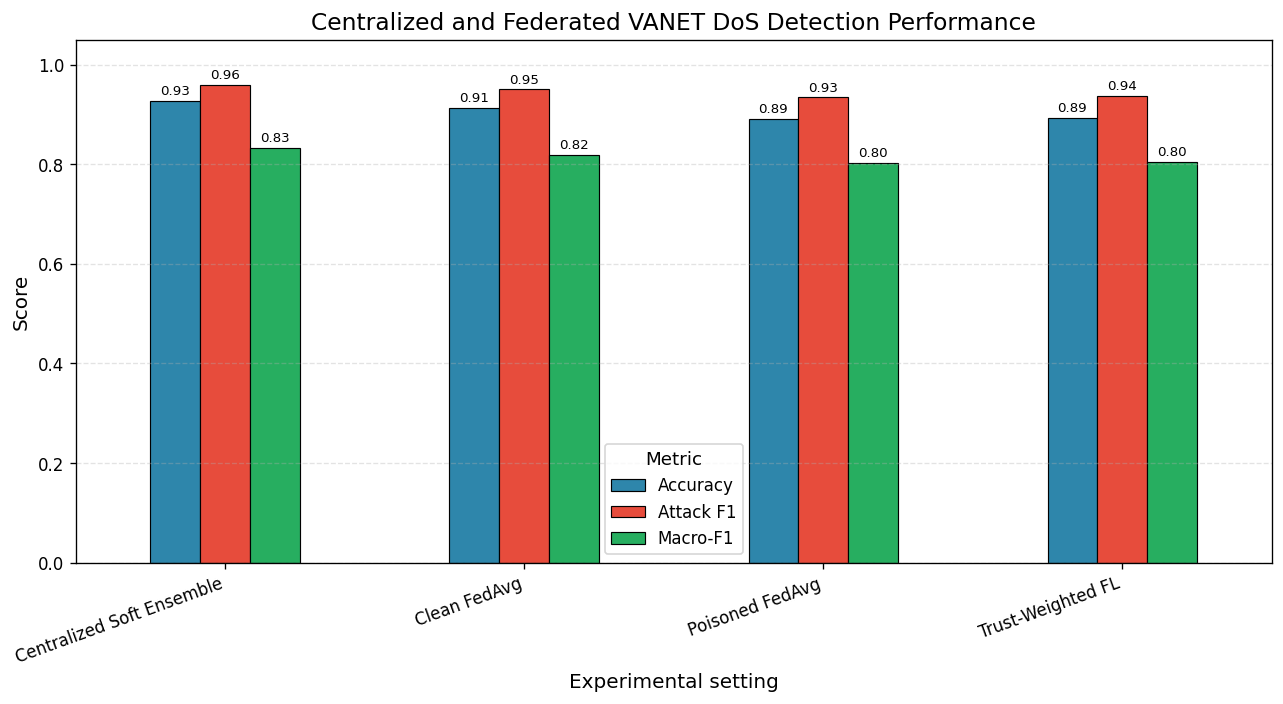

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_centralized_vs_federated_comparison.png


In [100]:
# ============================================================
# FIGURE: CENTRALIZED VS FEDERATED PERFORMANCE COMPARISON
# Purpose:
# Compare centralized, clean FL, poisoned FL, and trust-weighted FL.
# Update values if your variable names/results differ.
# ============================================================

# Extract metrics from final_fl_results_df
clean_equal_metrics = final_fl_results_df[
    final_fl_results_df["Model"] == "Federated Equal Aggregation Clean"
].iloc[0].to_dict()

poisoned_equal_metrics = final_fl_results_df[
    final_fl_results_df["Model"] == "Federated Equal Aggregation Poisoned"
].iloc[0].to_dict()

trust_weighted_metrics = final_fl_results_df[
    final_fl_results_df["Model"] == "Trust-Weighted FL Poisoned"
].iloc[0].to_dict()

fl_comparison_df = pd.DataFrame([
    {
        "Setting": "Centralized Soft Ensemble",
        "Accuracy": 0.92696,
        "Attack F1": 0.958252,
        "Macro-F1": 0.833303
    },
    {
        "Setting": "Clean FedAvg",
        "Accuracy": clean_equal_metrics["Accuracy"],
        "Attack F1": clean_equal_metrics["F1_Attack"],
        "Macro-F1": clean_equal_metrics["Macro_F1"]
    },
    {
        "Setting": "Poisoned FedAvg",
        "Accuracy": poisoned_equal_metrics["Accuracy"],
        "Attack F1": poisoned_equal_metrics["F1_Attack"],
        "Macro-F1": poisoned_equal_metrics["Macro_F1"]
    },
    {
        "Setting": "Trust-Weighted FL",
        "Accuracy": trust_weighted_metrics["Accuracy"],
        "Attack F1": trust_weighted_metrics["F1_Attack"],
        "Macro-F1": trust_weighted_metrics["Macro_F1"]
    }
])

plot_df = fl_comparison_df.set_index("Setting")

ax = plot_df.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#2E86AB", "#E74C3C", "#27AE60"],
    edgecolor="black",
    linewidth=0.7
)

plt.title("Centralized and Federated VANET DoS Detection Performance")
plt.xlabel("Experimental setting")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.35)
plt.legend(title="Metric")

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)

plt.tight_layout()

fig_path = f"{output_dir}/fig_centralized_vs_federated_comparison.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)


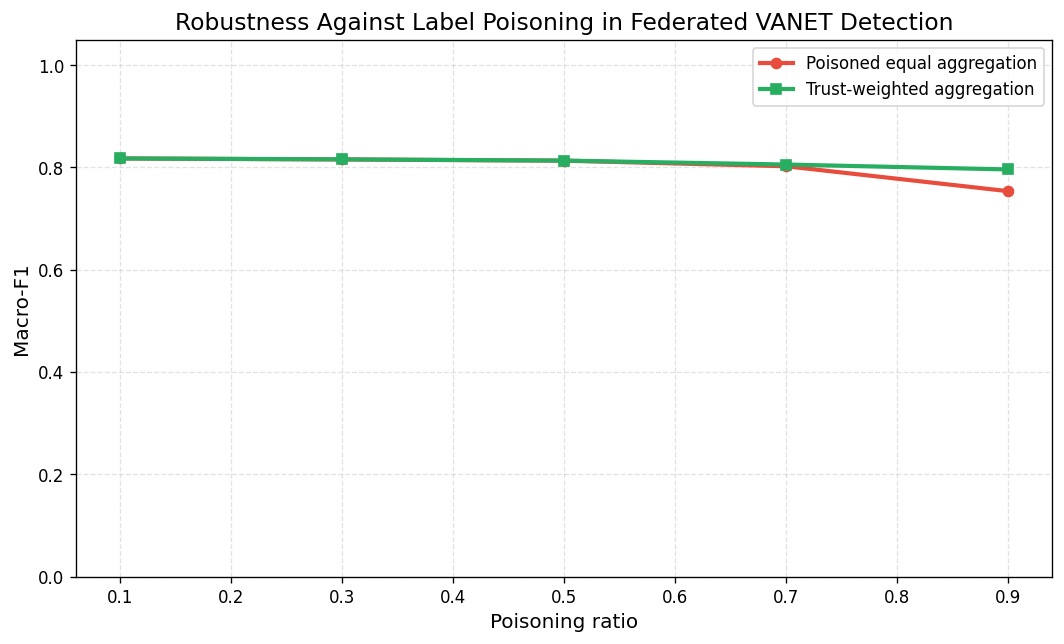

Saved figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_poisoning_robustness_macro_f1.png


In [101]:
import matplotlib.pyplot as plt

# Filter the robustness_df for each model type
equal_agg_df = robustness_df[robustness_df["Model"] == "Equal Aggregation"]
trust_weighted_agg_df = robustness_df[robustness_df["Model"] == "Trust-Weighted Aggregation"]

plt.figure(figsize=(9, 5.5))

plt.plot(
    equal_agg_df["Poison_Ratio"],
    equal_agg_df["Macro_F1"],
    marker="o",
    linewidth=2.5,
    color="#E74C3C",
    label="Poisoned equal aggregation"
)

plt.plot(
    trust_weighted_agg_df["Poison_Ratio"],
    trust_weighted_agg_df["Macro_F1"],
    marker="s",
    linewidth=2.5,
    color="#27AE60",
    label="Trust-weighted aggregation"
)

plt.xlabel("Poisoning ratio")
plt.ylabel("Macro-F1")
plt.title("Robustness Against Label Poisoning in Federated VANET Detection")
plt.ylim(0, 1.05)
plt.grid(linestyle="--", alpha=0.35)
plt.legend()
plt.tight_layout()

fig_path = f"{output_dir}/fig_poisoning_robustness_macro_f1.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", fig_path)

Using trust_poisoned_df
trust_poisoned_df columns: ['Client', 'Accuracy', 'Precision_Attack', 'Recall_Attack', 'F1_Attack', 'Macro_F1', 'Balanced_Accuracy', 'ROC_AUC', 'Trust', 'Normalized_Weight']


,Client,Trust
0,4,0.915416
1,3,0.912083
2,1,0.795569
3,0,0.790492
4,2,0.787161


Saved trust table: /content/drive/MyDrive/VANET_FL_RESULTS/client_trust_weights_table.csv


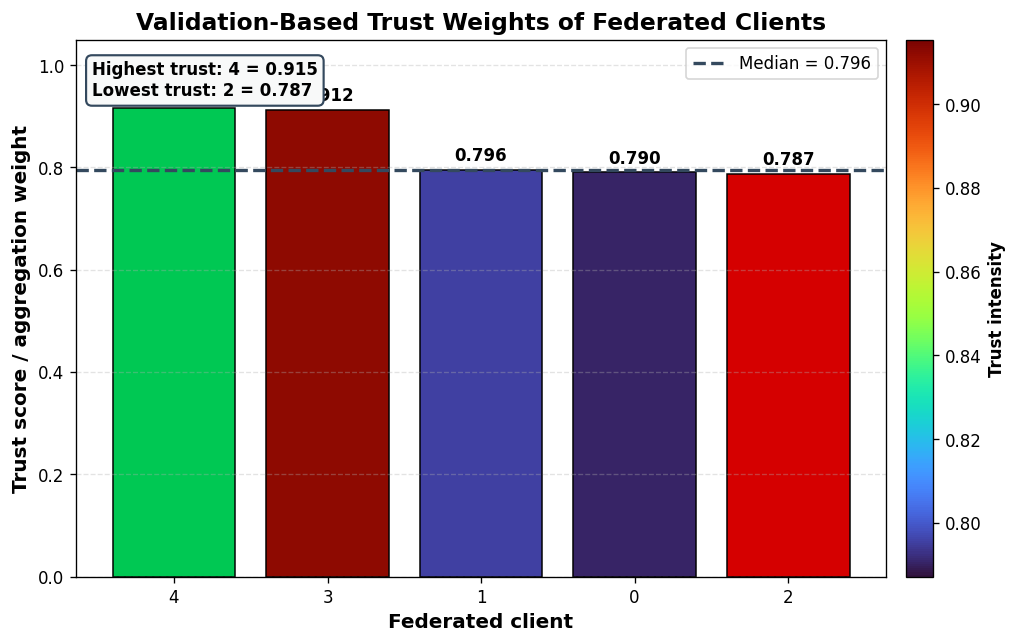

Saved colorful client trust figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_client_trust_weights_colorful.png


In [102]:
# ============================================================
# COLORFUL FIGURE: CLIENT TRUST WEIGHTS
# Purpose:
# Show client reliability/trust weights used in trust-weighted aggregation.
# Fixed for current notebook variables:
# - trust_poisoned_df
# - trust_weights_poisoned
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------
if "output_dir" not in globals():
    output_dir = "/content/drive/MyDrive/VANET_FL_RESULTS"
    os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Build client_trust_df from available notebook variables
# ------------------------------------------------------------
if "trust_poisoned_df" in globals() and isinstance(trust_poisoned_df, pd.DataFrame):
    print("Using trust_poisoned_df")
    print("trust_poisoned_df columns:", trust_poisoned_df.columns.tolist())

    temp_df = trust_poisoned_df.copy()

    # Detect client column
    possible_client_cols = ["Client", "client", "Client_ID", "client_id", "cid", "ClientID"]
    client_col = None
    for col in possible_client_cols:
        if col in temp_df.columns:
            client_col = col
            break

    # Detect trust/weight column
    possible_trust_cols = [
        "Trust", "trust", "Trust_Score", "trust_score",
        "Weight", "weight", "Client_Weight", "client_weight",
        "Normalized_Trust", "normalized_trust",
        "Trust_Weight", "trust_weight"
    ]
    trust_col = None
    for col in possible_trust_cols:
        if col in temp_df.columns:
            trust_col = col
            break

    # If client column missing, use row number
    if client_col is None:
        temp_df = temp_df.reset_index(drop=True)
        temp_df["Client"] = [f"Client {i}" for i in range(len(temp_df))]
        client_col = "Client"

    # If trust column missing, use last numeric column
    if trust_col is None:
        numeric_cols = temp_df.select_dtypes(include=[np.number]).columns.tolist()
        if len(numeric_cols) == 0:
            raise ValueError("trust_poisoned_df has no numeric trust/weight column.")
        trust_col = numeric_cols[-1]
        print("Auto-selected trust column:", trust_col)

    client_trust_df_fixed = temp_df[[client_col, trust_col]].copy()
    client_trust_df_fixed.columns = ["Client", "Trust"]

elif "trust_weights_poisoned" in globals():
    print("Using trust_weights_poisoned")

    weights_array = np.asarray(trust_weights_poisoned).ravel()

    client_trust_df_fixed = pd.DataFrame({
        "Client": [f"Client {i}" for i in range(len(weights_array))],
        "Trust": weights_array
    })

elif "weights" in globals():
    print("Using weights")

    weights_array = np.asarray(weights).ravel()

    client_trust_df_fixed = pd.DataFrame({
        "Client": [f"Client {i}" for i in range(len(weights_array))],
        "Trust": weights_array
    })

else:
    raise ValueError(
        "No trust variable found. Run the trust-weighted FL cell first. "
        "Expected one of: trust_poisoned_df, trust_weights_poisoned, weights."
    )

# ------------------------------------------------------------
# Clean trust values
# ------------------------------------------------------------
client_trust_df_fixed["Trust"] = pd.to_numeric(
    client_trust_df_fixed["Trust"],
    errors="coerce"
)

client_trust_df_fixed = client_trust_df_fixed.dropna(subset=["Trust"]).copy()

# If values are percentages or raw scores greater than 1, normalize to 0–1
if client_trust_df_fixed["Trust"].max() > 1.0:
    min_v = client_trust_df_fixed["Trust"].min()
    max_v = client_trust_df_fixed["Trust"].max()
    client_trust_df_fixed["Trust"] = (
        client_trust_df_fixed["Trust"] - min_v
    ) / (max_v - min_v + 1e-9)

client_trust_df_fixed = client_trust_df_fixed.sort_values(
    by="Trust",
    ascending=False
).reset_index(drop=True)

display(client_trust_df_fixed)

# Save table
trust_table_path = f"{output_dir}/client_trust_weights_table.csv"
client_trust_df_fixed.to_csv(trust_table_path, index=False)
print("Saved trust table:", trust_table_path)

# ------------------------------------------------------------
# Colorful plot
# ------------------------------------------------------------
values = client_trust_df_fixed["Trust"].values

norm = mcolors.Normalize(vmin=values.min(), vmax=values.max())
cmap = cm.get_cmap("turbo")   # colorful
colors = [cmap(norm(v)) for v in values]

# Highlight best and lowest clients
best_idx = client_trust_df_fixed["Trust"].idxmax()
worst_idx = client_trust_df_fixed["Trust"].idxmin()

colors[best_idx] = "#00C853"   # bright green
colors[worst_idx] = "#D50000"  # red

plt.figure(figsize=(9, 5.5))

bars = plt.bar(
    client_trust_df_fixed["Client"].astype(str),
    client_trust_df_fixed["Trust"],
    color=colors,
    edgecolor="black",
    linewidth=0.9
)

plt.xlabel("Federated client", fontsize=12, fontweight="bold")
plt.ylabel("Trust score / aggregation weight", fontsize=12, fontweight="bold")
plt.title(
    "Validation-Based Trust Weights of Federated Clients",
    fontsize=14,
    fontweight="bold"
)

plt.ylim(0, max(1.05, values.max() + 0.08))
plt.grid(axis="y", linestyle="--", alpha=0.35)

median_trust = client_trust_df_fixed["Trust"].median()

plt.axhline(
    y=median_trust,
    color="#34495E",
    linestyle="--",
    linewidth=2,
    label=f"Median = {median_trust:.3f}"
)

# Value labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height:.3f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# Annotation box
best_client = client_trust_df_fixed.loc[best_idx, "Client"]
best_value = client_trust_df_fixed.loc[best_idx, "Trust"]

worst_client = client_trust_df_fixed.loc[worst_idx, "Client"]
worst_value = client_trust_df_fixed.loc[worst_idx, "Trust"]

plt.text(
    0.02,
    0.96,
    f"Highest trust: {best_client} = {best_value:.3f}\nLowest trust: {worst_client} = {worst_value:.3f}",
    transform=plt.gca().transAxes,
    fontsize=10,
    fontweight="bold",
    va="top",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="#F8F9F9",
        edgecolor="#34495E",
        linewidth=1.3
    )
)

# Colorbar
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label("Trust intensity", fontsize=10, fontweight="bold")

plt.legend(loc="upper right")
plt.tight_layout()

fig_path = f"{output_dir}/fig_client_trust_weights_colorful.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved colorful client trust figure:", fig_path)

Available columns in ablation_df:
['Ablation_Mode', 'Accuracy', 'Precision_Attack', 'Recall_Attack', 'F1_Attack', 'Macro_F1', 'Balanced_Accuracy', 'ROC_AUC']


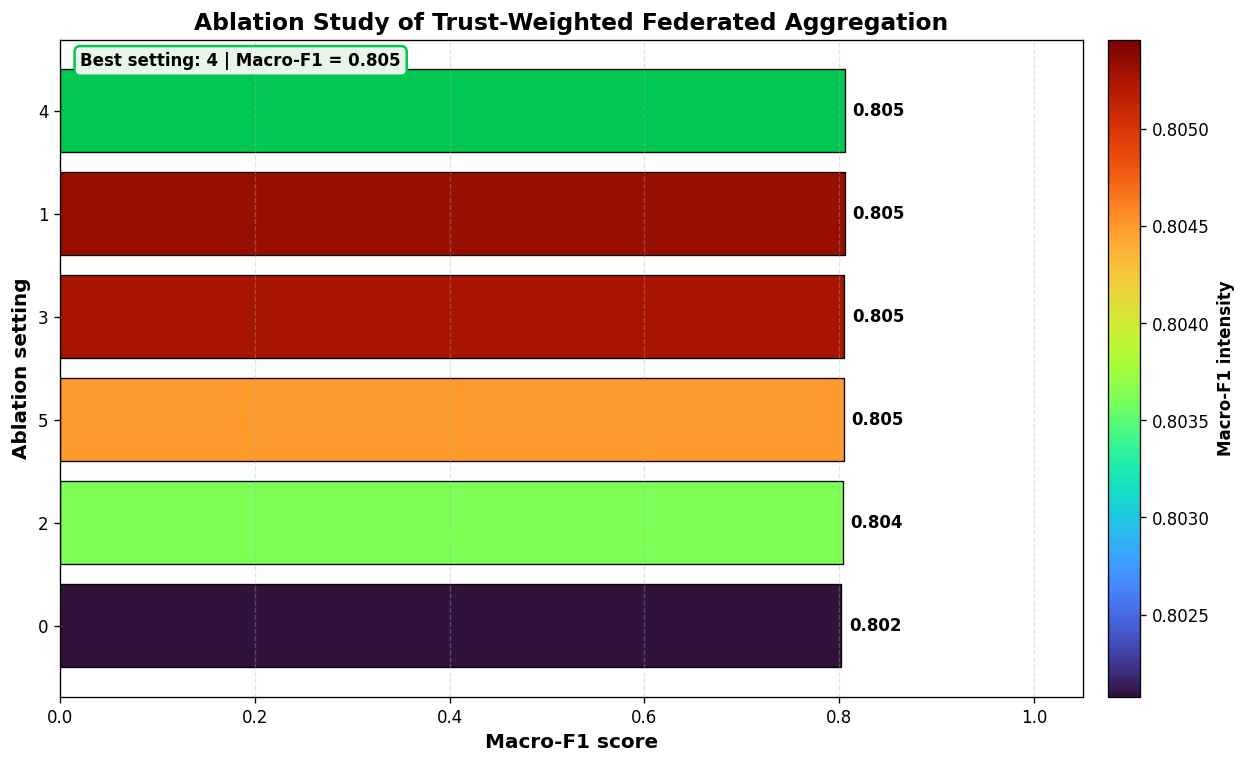

Saved colorful ablation figure: /content/drive/MyDrive/VANET_FL_RESULTS/fig_ablation_macro_f1_colorful.png


In [103]:
# ============================================================
# COLORFUL FIGURE: ABLATION STUDY
# Purpose:
# Show contribution of trust components / feature groups.
# Robust version:
# - Handles missing "Setting" column
# - Automatically detects Macro-F1 column
# - Uses colorful gradient + highlights best setting
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
if "ablation_df" not in globals():
    raise ValueError("ablation_df not found. Please run the ablation study cell first.")

if "output_dir" not in globals():
    output_dir = "/content/drive/MyDrive/VANET_FL_RESULTS"
    os.makedirs(output_dir, exist_ok=True)

print("Available columns in ablation_df:")
print(ablation_df.columns.tolist())

ablation_plot_df = ablation_df.copy()

# ------------------------------------------------------------
# Detect ablation-setting column
# ------------------------------------------------------------
possible_setting_cols = [
    "Setting", "Ablation", "Variant", "Method", "Model",
    "Trust_Setting", "Configuration", "Experiment", "Component"
]

setting_col = None
for col in possible_setting_cols:
    if col in ablation_plot_df.columns:
        setting_col = col
        break

# If no setting column exists, use index
if setting_col is None:
    ablation_plot_df = ablation_plot_df.reset_index()
    ablation_plot_df = ablation_plot_df.rename(columns={"index": "Setting"})
    setting_col = "Setting"

# ------------------------------------------------------------
# Detect Macro-F1 column
# ------------------------------------------------------------
possible_metric_cols = [
    "Macro_F1", "Macro-F1", "macro_f1", "Macro F1",
    "F1_Macro", "f1_macro", "macro avg f1-score"
]

metric_col = None
for col in possible_metric_cols:
    if col in ablation_plot_df.columns:
        metric_col = col
        break

if metric_col is None:
    raise KeyError(
        "No Macro-F1 column found. Available columns are: "
        + str(ablation_plot_df.columns.tolist())
    )

# ------------------------------------------------------------
# Clean metric values
# ------------------------------------------------------------
ablation_plot_df[metric_col] = pd.to_numeric(
    ablation_plot_df[metric_col],
    errors="coerce"
)

ablation_plot_df = ablation_plot_df.dropna(subset=[metric_col])

# Sort low to high for horizontal bar chart
ablation_plot_df = ablation_plot_df.sort_values(
    by=metric_col,
    ascending=True
).reset_index(drop=True)

# ------------------------------------------------------------
# Colorful gradient based on Macro-F1 values
# Low = red/orange, high = green/blue
# ------------------------------------------------------------
values = ablation_plot_df[metric_col].values

norm = mcolors.Normalize(vmin=values.min(), vmax=values.max())
cmap = cm.get_cmap("turbo")   # very colorful; alternatives: "viridis", "plasma", "rainbow"
colors = [cmap(norm(v)) for v in values]

# Highlight best setting with bright green
best_idx = ablation_plot_df[metric_col].idxmax()
colors[best_idx] = "#00C853"   # bright green

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------
plt.figure(figsize=(11, 6.5))

bars = plt.barh(
    ablation_plot_df[setting_col].astype(str),
    ablation_plot_df[metric_col],
    color=colors,
    edgecolor="black",
    linewidth=0.8
)

plt.xlabel("Macro-F1 score", fontsize=12, fontweight="bold")
plt.ylabel("Ablation setting", fontsize=12, fontweight="bold")
plt.title(
    "Ablation Study of Trust-Weighted Federated Aggregation",
    fontsize=14,
    fontweight="bold"
)

plt.xlim(0, 1.05)
plt.grid(axis="x", linestyle="--", alpha=0.35)

# ------------------------------------------------------------
# Add value labels
# ------------------------------------------------------------
for i, bar in enumerate(bars):
    width = bar.get_width()
    label = f"{width:.3f}"

    plt.text(
        width + 0.008,
        bar.get_y() + bar.get_height() / 2,
        label,
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color="black"
    )

# ------------------------------------------------------------
# Add best-setting annotation
# ------------------------------------------------------------
best_setting = str(ablation_plot_df.loc[best_idx, setting_col])
best_value = ablation_plot_df.loc[best_idx, metric_col]

plt.text(
    0.02,
    0.96,
    f"Best setting: {best_setting} | Macro-F1 = {best_value:.3f}",
    transform=plt.gca().transAxes,
    fontsize=10,
    fontweight="bold",
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="#E8F5E9",
        edgecolor="#00C853",
        linewidth=1.5
    )
)

# ------------------------------------------------------------
# Add colorbar for metric intensity
# ------------------------------------------------------------
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label("Macro-F1 intensity", fontsize=10, fontweight="bold")

plt.tight_layout()

fig_path = f"{output_dir}/fig_ablation_macro_f1_colorful.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved colorful ablation figure:", fig_path)

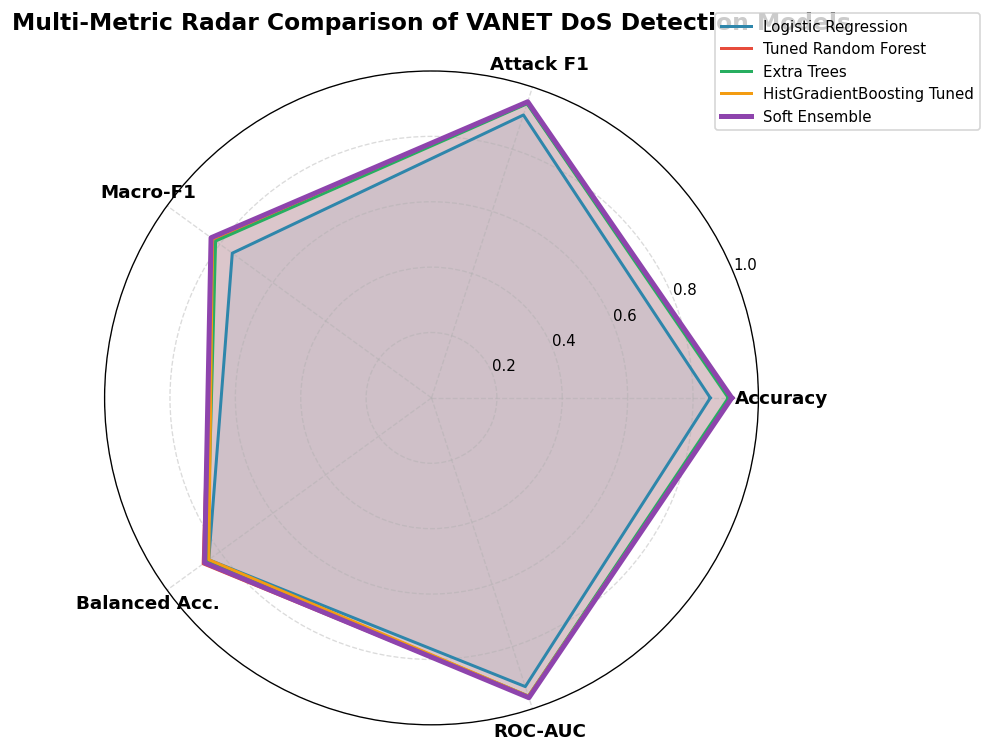

Saved colorful radar chart: /content/drive/MyDrive/VANET_FL_RESULTS/fig_radar_model_comparison_colorful.png


In [104]:
# ============================================================
# COLORFUL FIGURE: RADAR CHART FOR MODEL COMPARISON
# Purpose:
# Compare centralized VANET DoS detection models across multiple metrics.
# Requires: results_90_df
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Output directory
# ------------------------------------------------------------
if "output_dir" not in globals():
    output_dir = "/content/drive/MyDrive/VANET_FL_RESULTS"
    os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------------------
# Safety check
# ------------------------------------------------------------
if "results_90_df" not in globals():
    raise ValueError("results_90_df not found. Please run the 90% model comparison cell first.")

# ------------------------------------------------------------
# Select metrics for radar chart
# ------------------------------------------------------------
radar_metrics = [
    "Accuracy",
    "F1_Attack",
    "Macro_F1",
    "Balanced_Accuracy",
    "ROC_AUC"
]

missing_cols = [c for c in radar_metrics + ["Model"] if c not in results_90_df.columns]
if len(missing_cols) > 0:
    raise KeyError(f"Missing columns in results_90_df: {missing_cols}")

radar_df = results_90_df[["Model"] + radar_metrics].copy()

# Rename metrics for cleaner figure labels
metric_labels = [
    "Accuracy",
    "Attack F1",
    "Macro-F1",
    "Balanced Acc.",
    "ROC-AUC"
]

# ------------------------------------------------------------
# Radar chart setup
# ------------------------------------------------------------
num_vars = len(radar_metrics)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]

# Color palette
model_colors = [
    "#2E86AB",  # blue
    "#E74C3C",  # red
    "#27AE60",  # green
    "#F39C12",  # orange
    "#8E44AD",  # purple
    "#16A085",  # teal
    "#D35400"   # dark orange
]

plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)

# ------------------------------------------------------------
# Plot each model
# ------------------------------------------------------------
for idx, row in radar_df.iterrows():
    values = row[radar_metrics].astype(float).tolist()
    values += values[:1]

    color = model_colors[idx % len(model_colors)]

    linewidth = 3 if "Soft Ensemble" in str(row["Model"]) else 1.8
    alpha_fill = 0.18 if "Soft Ensemble" in str(row["Model"]) else 0.08

    ax.plot(
        angles,
        values,
        color=color,
        linewidth=linewidth,
        label=row["Model"]
    )

    ax.fill(
        angles,
        values,
        color=color,
        alpha=alpha_fill
    )

# ------------------------------------------------------------
# Axis formatting
# ------------------------------------------------------------
ax.set_xticks(angles[:-1])
ax.set_xticklabels(metric_labels, fontsize=11, fontweight="bold")

ax.set_ylim(0, 1.0)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=9)

ax.set_title(
    "Multi-Metric Radar Comparison of VANET DoS Detection Models",
    fontsize=14,
    fontweight="bold",
    pad=25
)

ax.grid(True, linestyle="--", alpha=0.45)

plt.legend(
    loc="upper right",
    bbox_to_anchor=(1.35, 1.10),
    fontsize=9,
    frameon=True
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------
fig_path = f"{output_dir}/fig_radar_model_comparison_colorful.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved colorful radar chart:", fig_path)